         DATASET LUNA16 — EXPLORATION COMPLETE

Chemin base : /kaggle/input/datasets/tessnimetteib/luna16-dataset

Fichiers CSV :
  sampleSubmission.csv                (0.7 KB)
  annotations.csv                     (133.8 KB)
  candidates.csv                      (54128.8 KB)

Repartition des scans par subset :
  subset3 (1)          : 89 scans
  subset4              : 89 scans
  subset5              : 89 scans
  subset6              : 89 scans
  subset7              : 89 scans
  subset8              : 88 scans
  subset9              : 88 scans

Total scans CT (.mhd) : 1509
Total compte          : 621


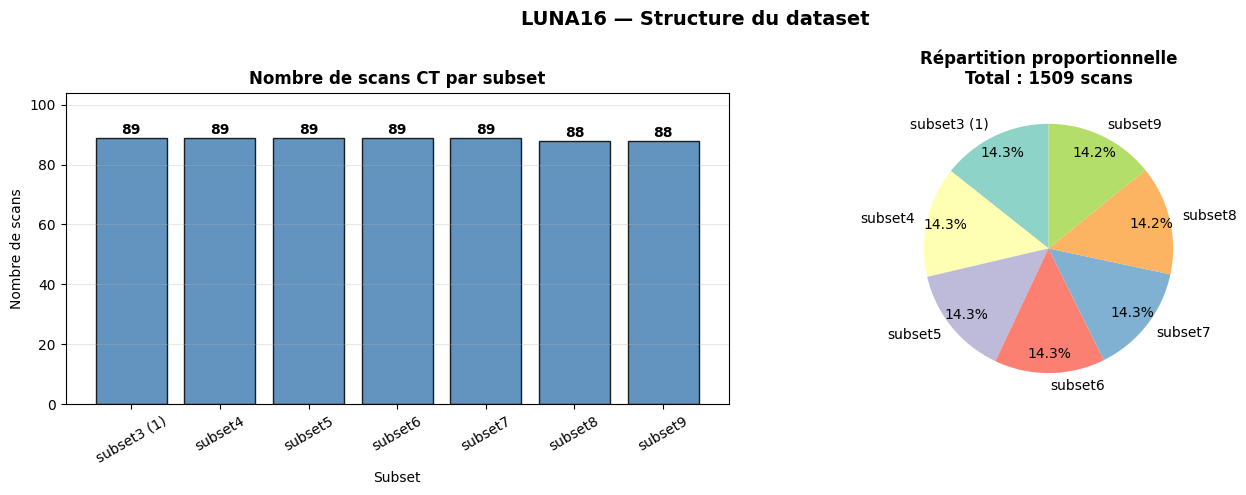

In [1]:
import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import random
import gc
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------ #
# CHEMINS
# ------------------------------------------------------------------ #
BASE_PATH = '/kaggle/input/datasets/tessnimetteib/luna16-dataset'

# ------------------------------------------------------------------ #
# EXPLORATION COMPLETE DU DATASET
# ------------------------------------------------------------------ #
mhd_files     = []
subset_counts = {}

for root, dirs, files in os.walk(BASE_PATH):
    for f in files:
        if f.endswith('.mhd'):
            mhd_files.append(os.path.join(root, f))
            parts = root.replace(BASE_PATH, '').split(os.sep)
            subset_name = [p for p in parts if 'subset' in p.lower()]
            if subset_name:
                key = subset_name[0]
                subset_counts[key] = subset_counts.get(key, 0) + 1

csv_files = [f for f in os.listdir(BASE_PATH) if f.endswith('.csv')]

print("=" * 60)
print("         DATASET LUNA16 — EXPLORATION COMPLETE")
print("=" * 60)
print(f"\nChemin base : {BASE_PATH}")
print(f"\nFichiers CSV :")
for c in csv_files:
    size = os.path.getsize(os.path.join(BASE_PATH, c)) / 1024
    print(f"  {c:<35} ({size:.1f} KB)")

print(f"\nRepartition des scans par subset :")
total = 0
for k in sorted(subset_counts.keys()):
    print(f"  {k:<20} : {subset_counts[k]} scans")
    total += subset_counts[k]

print(f"\nTotal scans CT (.mhd) : {len(mhd_files)}")
print(f"Total compte          : {total}")

# ------------------------------------------------------------------ #
# VISUALISATION — REPARTITION PAR SUBSET
# ------------------------------------------------------------------ #
subsets = sorted(subset_counts.keys())
counts  = [subset_counts[s] for s in subsets]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot
bars = axes[0].bar(subsets, counts, color='steelblue', edgecolor='black', alpha=0.85)
for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Nombre de scans CT par subset', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Subset')
axes[0].set_ylabel('Nombre de scans')
axes[0].set_ylim(0, max(counts) + 15)
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
axes[1].pie(counts, labels=subsets, autopct='%1.1f%%',
            colors=plt.cm.Set3.colors[:len(subsets)],
            startangle=90, pctdistance=0.85)
axes[1].set_title(f'Répartition proportionnelle\nTotal : {len(mhd_files)} scans',
                  fontsize=12, fontweight='bold')

plt.suptitle('LUNA16 — Structure du dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/01_exploration_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

        FICHIER annotations.csv
Shape          : (1186, 5)
Colonnes       : ['seriesuid', 'coordX', 'coordY', 'coordZ', 'diameter_mm']

Premieres lignes :
                                           seriesuid      coordX      coordY  \
0  1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222... -128.699421 -175.319272   
1  1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...  103.783651 -211.925149   
2  1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...   69.639017 -140.944586   
3  1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...  -24.013824  192.102405   
4  1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...    2.441547  172.464881   

       coordZ  diameter_mm  
0 -298.387506     5.651471  
1 -227.121250     4.224708  
2  876.374496     5.786348  
3 -391.081276     8.143262  
4 -405.493732    18.545150  

Valeurs manquantes :
seriesuid      0
coordX         0
coordY         0
coordZ         0
diameter_mm    0
dtype: int64

        FICHIER candidates.csv
Shape          : (551065, 5)
Colonnes 

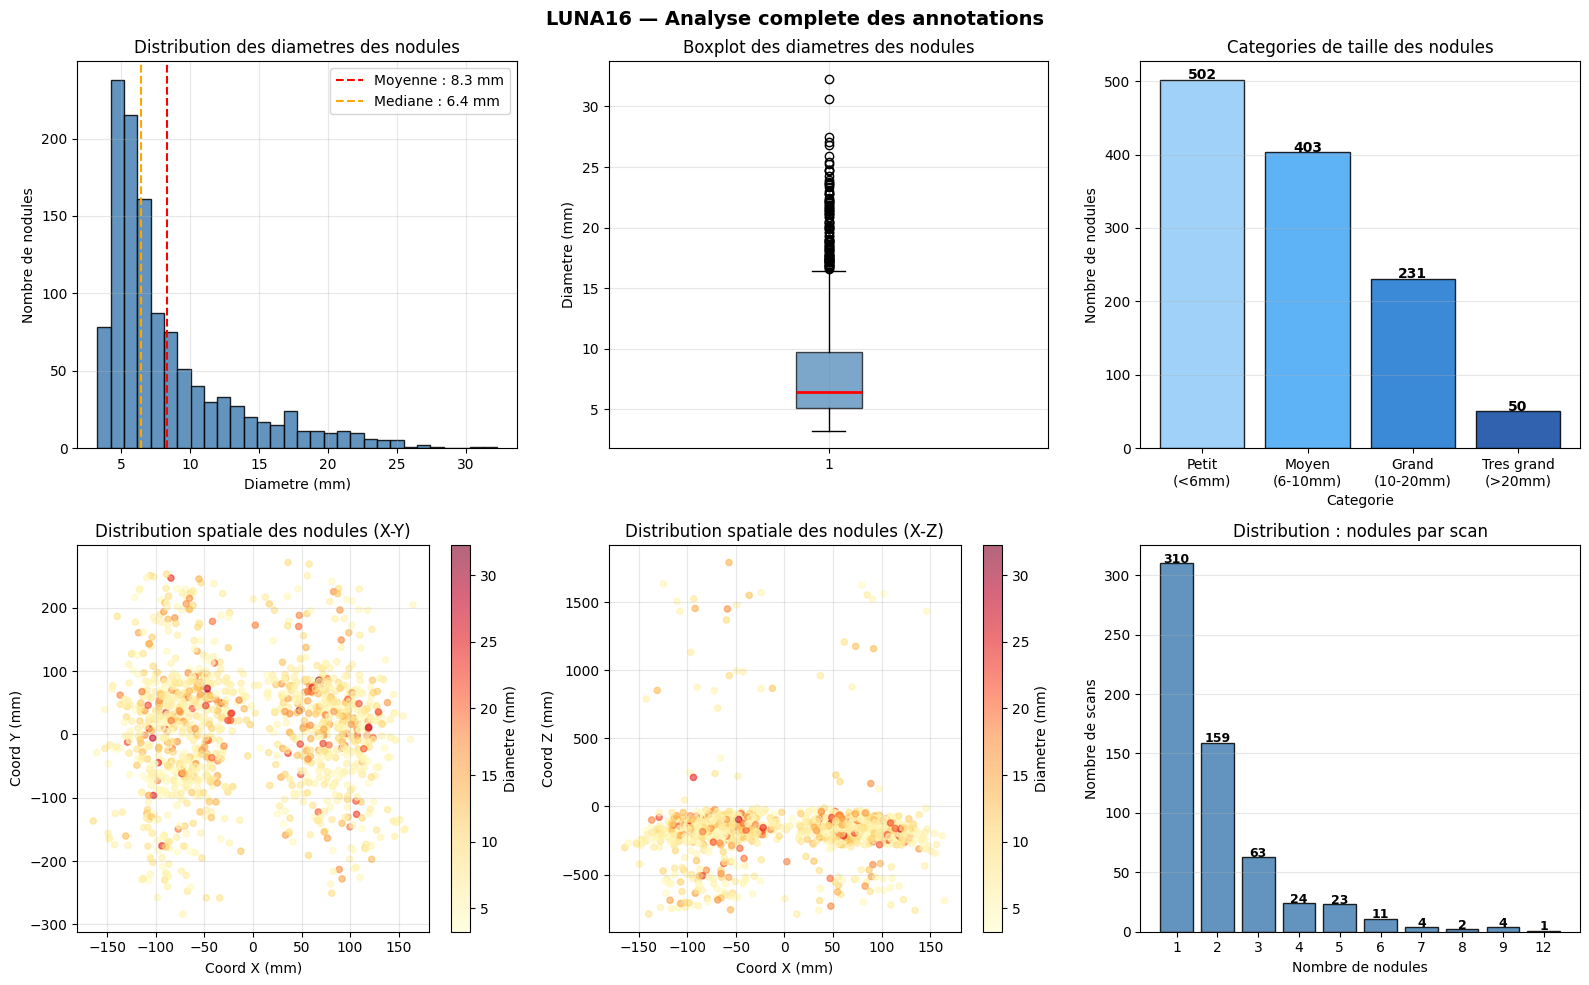

In [2]:
# ------------------------------------------------------------------ #
# CELLULE 2 — CHARGEMENT ET ANALYSE DES ANNOTATIONS
# ------------------------------------------------------------------ #

annotations = pd.read_csv(os.path.join(BASE_PATH, 'annotations.csv'))
candidates  = pd.read_csv(os.path.join(BASE_PATH, 'candidates.csv'))

print("=" * 60)
print("        FICHIER annotations.csv")
print("=" * 60)
print(f"Shape          : {annotations.shape}")
print(f"Colonnes       : {annotations.columns.tolist()}")
print(f"\nPremieres lignes :")
print(annotations.head())
print(f"\nValeurs manquantes :\n{annotations.isnull().sum()}")

print("\n" + "=" * 60)
print("        FICHIER candidates.csv")
print("=" * 60)
print(f"Shape          : {candidates.shape}")
print(f"Colonnes       : {candidates.columns.tolist()}")
print(f"\nRepartition des classes :")
print(candidates['class'].value_counts())
print(f"\nPourcentage positifs : {100*candidates['class'].mean():.3f}%")

print("\n" + "=" * 60)
print("        STATISTIQUES DES NODULES")
print("=" * 60)
print(f"Nombre total de nodules       : {len(annotations)}")
print(f"Nombre de scans avec nodules  : {annotations['seriesuid'].nunique()}")
print(f"Nodules par scan (moyenne)    : {len(annotations)/annotations['seriesuid'].nunique():.2f}")
print(f"\nStatistiques des diametres (mm) :")
print(annotations['diameter_mm'].describe().round(2))

# Categories de taille
bins_size   = [0, 6, 10, 20, 100]
labels_size = ['Petit\n(<6mm)', 'Moyen\n(6-10mm)', 'Grand\n(10-20mm)', 'Tres grand\n(>20mm)']
annotations['size_cat'] = pd.cut(annotations['diameter_mm'],
                                  bins=bins_size, labels=labels_size)
size_counts = annotations['size_cat'].value_counts().sort_index()

nodules_per_scan = annotations.groupby('seriesuid').size().sort_values(ascending=False)
print(f"\nDistribution du nombre de nodules par scan :")
print(nodules_per_scan.value_counts().sort_index().to_string())

# ------------------------------------------------------------------ #
# VISUALISATIONS
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Histogramme des diametres
axes[0,0].hist(annotations['diameter_mm'], bins=30,
               color='steelblue', edgecolor='black', alpha=0.85)
axes[0,0].axvline(annotations['diameter_mm'].mean(),
                   color='red', linestyle='--',
                   label=f"Moyenne : {annotations['diameter_mm'].mean():.1f} mm")
axes[0,0].axvline(annotations['diameter_mm'].median(),
                   color='orange', linestyle='--',
                   label=f"Mediane : {annotations['diameter_mm'].median():.1f} mm")
axes[0,0].set_title('Distribution des diametres des nodules')
axes[0,0].set_xlabel('Diametre (mm)')
axes[0,0].set_ylabel('Nombre de nodules')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# 2. Boxplot des diametres
axes[0,1].boxplot(annotations['diameter_mm'], patch_artist=True,
                   boxprops=dict(facecolor='steelblue', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[0,1].set_title('Boxplot des diametres des nodules')
axes[0,1].set_ylabel('Diametre (mm)')
axes[0,1].grid(alpha=0.3)

# 3. Categories de taille
colors_cat = ['#90CAF9', '#42A5F5', '#1976D2', '#0D47A1']
bars = axes[0,2].bar(size_counts.index, size_counts.values,
                      color=colors_cat, edgecolor='black', alpha=0.85)
for bar, v in zip(bars, size_counts.values):
    axes[0,2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    str(v), ha='center', fontweight='bold')
axes[0,2].set_title('Categories de taille des nodules')
axes[0,2].set_xlabel('Categorie')
axes[0,2].set_ylabel('Nombre de nodules')
axes[0,2].grid(axis='y', alpha=0.3)

# 4. Distribution spatiale X-Y
sc1 = axes[1,0].scatter(annotations['coordX'], annotations['coordY'],
                         c=annotations['diameter_mm'], cmap='YlOrRd',
                         alpha=0.6, s=20)
plt.colorbar(sc1, ax=axes[1,0], label='Diametre (mm)')
axes[1,0].set_title('Distribution spatiale des nodules (X-Y)')
axes[1,0].set_xlabel('Coord X (mm)')
axes[1,0].set_ylabel('Coord Y (mm)')
axes[1,0].grid(alpha=0.3)

# 5. Distribution spatiale X-Z
sc2 = axes[1,1].scatter(annotations['coordX'], annotations['coordZ'],
                         c=annotations['diameter_mm'], cmap='YlOrRd',
                         alpha=0.6, s=20)
plt.colorbar(sc2, ax=axes[1,1], label='Diametre (mm)')
axes[1,1].set_title('Distribution spatiale des nodules (X-Z)')
axes[1,1].set_xlabel('Coord X (mm)')
axes[1,1].set_ylabel('Coord Z (mm)')
axes[1,1].grid(alpha=0.3)

# 6. Nombre de nodules par scan
dist_counts = nodules_per_scan.value_counts().sort_index()
axes[1,2].bar(dist_counts.index.astype(str), dist_counts.values,
               color='steelblue', edgecolor='black', alpha=0.85)
for i, v in enumerate(dist_counts.values):
    axes[1,2].text(i, v + 0.3, str(v), ha='center', fontweight='bold', fontsize=9)
axes[1,2].set_title('Distribution : nodules par scan')
axes[1,2].set_xlabel('Nombre de nodules')
axes[1,2].set_ylabel('Nombre de scans')
axes[1,2].grid(axis='y', alpha=0.3)

plt.suptitle('LUNA16 — Analyse complete des annotations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/02_analyse_annotations.png', dpi=150, bbox_inches='tight')
plt.show()


In [3]:
# ------------------------------------------------------------------ #
# CELLULE 3 — FONCTIONS DE PRETRAITEMENT
# ------------------------------------------------------------------ #

def load_ct_scan(mhd_path):
    """Charge un scan CT et retourne le volume numpy + metadata."""
    itk_img  = sitk.ReadImage(mhd_path)
    img      = sitk.GetArrayFromImage(itk_img)
    origin   = np.array(itk_img.GetOrigin())
    spacing  = np.array(itk_img.GetSpacing())
    try:
        slope     = float(itk_img.GetMetaData('0028|1053')) if itk_img.HasMetaDataKey('0028|1053') else 1.0
        intercept = float(itk_img.GetMetaData('0028|1052')) if itk_img.HasMetaDataKey('0028|1052') else 0.0
    except:
        slope, intercept = 1.0, 0.0
    img = img * slope + intercept
    return img, origin, spacing

def clip_hu(img, hu_min=-1000, hu_max=400):
    """Clipping HU entre -1000 (air) et +400 (os)."""
    return np.clip(img, hu_min, hu_max)

def normalize_hu(img):
    """Normalisation z-score."""
    mean = img.mean()
    std  = img.std()
    return (img - mean) / (std + 1e-8)

def world_to_voxel(coord_world, origin, spacing):
    """Convertit coordonnees monde (mm) en indices voxels (z, y, x)."""
    x = int(round((coord_world[0] - origin[0]) / spacing[0]))
    y = int(round((coord_world[1] - origin[1]) / spacing[1]))
    z = int(round((coord_world[2] - origin[2]) / spacing[2]))
    return (z, y, x)

def extract_patch(scan, center_zyx, patch_size=(32, 48, 48)):
    """Extrait un patch 3D centre sur center_zyx avec padding si necessaire."""
    z, y, x    = center_zyx
    pz, py, px = patch_size

    z0 = max(0, z - pz // 2); z1 = z0 + pz
    y0 = max(0, y - py // 2); y1 = y0 + py
    x0 = max(0, x - px // 2); x1 = x0 + px

    z1 = min(scan.shape[0], z1); z0 = z1 - pz
    y1 = min(scan.shape[1], y1); y0 = y1 - py
    x1 = min(scan.shape[2], x1); x0 = x1 - px

    z0 = max(0, z0); y0 = max(0, y0); x0 = max(0, x0)

    patch = scan[z0:z1, y0:y1, x0:x1]

    if patch.shape != tuple(patch_size):
        pad   = [(0, pz - patch.shape[0]),
                 (0, py - patch.shape[1]),
                 (0, px - patch.shape[2])]
        patch = np.pad(patch, pad, mode='constant', constant_values=0)

    return patch

# ------------------------------------------------------------------ #
# MAPPING uid -> chemin .mhd
# ------------------------------------------------------------------ #
uid_to_path = {os.path.basename(p).replace('.mhd', ''): p for p in mhd_files}

matched = []
for _, row in annotations.iterrows():
    uid = row['seriesuid']
    if uid in uid_to_path:
        matched.append({
            'mhd_path'   : uid_to_path[uid],
            'coord_world': (row['coordX'], row['coordY'], row['coordZ']),
            'diameter'   : row['diameter_mm']
        })

nodules_by_scan = {}
for n in matched:
    nodules_by_scan.setdefault(n['mhd_path'], []).append(n)

print("=" * 60)
print("        TEST DES FONCTIONS")
print("=" * 60)
print(f"Nodules matches         : {len(matched)} / {len(annotations)}")
print(f"Scans avec nodules      : {len(nodules_by_scan)}")

# Trouver un scan valide pour le test
test_path = None
for path in list(nodules_by_scan.keys())[:30]:
    try:
        s, _, _ = load_ct_scan(path)
        if s.min() < -100:
            test_path = path
            del s
            break
    except:
        continue

scan_raw, origin, spacing = load_ct_scan(test_path)
print(f"\nScan teste              : {os.path.basename(test_path)}")
print(f"Shape (Z, Y, X)         : {scan_raw.shape}")
print(f"Origin (mm)             : {origin}")
print(f"Spacing (mm/voxel)      : {spacing}")
print(f"HU brut min/max         : {scan_raw.min():.0f} / {scan_raw.max():.0f}")

scan_clipped = clip_hu(scan_raw)
print(f"HU apres clipping       : {scan_clipped.min():.0f} / {scan_clipped.max():.0f}")

scan_norm = normalize_hu(scan_clipped)
print(f"Apres normalisation     : mean={scan_norm.mean():.4f}, std={scan_norm.std():.4f}")

# Test world_to_voxel
nodule_test  = nodules_by_scan[test_path][0]
coord_world  = nodule_test['coord_world']
coord_voxel  = world_to_voxel(coord_world, origin, spacing)
in_bounds    = (0 <= coord_voxel[0] < scan_raw.shape[0] and
                0 <= coord_voxel[1] < scan_raw.shape[1] and
                0 <= coord_voxel[2] < scan_raw.shape[2])
print(f"\nTest world_to_voxel     :")
print(f"  Coord monde (mm)      : {coord_world}")
print(f"  Coord voxel (z,y,x)   : {coord_voxel}")
print(f"  Dans le volume        : {in_bounds}")

# Test extract_patch
patch_test = extract_patch(scan_norm, coord_voxel)
print(f"\nTest extract_patch      :")
print(f"  Shape patch           : {patch_test.shape}")
print(f"  Min / Max             : {patch_test.min():.3f} / {patch_test.max():.3f}")

del scan_raw, scan_clipped, scan_norm
gc.collect()



        TEST DES FONCTIONS
Nodules matches         : 1186 / 1186
Scans avec nodules      : 601

Scan teste              : 1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
Shape (Z, Y, X)         : (194, 512, 512)
Origin (mm)             : [-157.67773 -311.67773 -438.4    ]
Spacing (mm/voxel)      : [0.64453125 0.64453125 1.79999995]
HU brut min/max         : -1024 / 3071
HU apres clipping       : -1000 / 400
Apres normalisation     : mean=0.0000, std=1.0000

Test world_to_voxel     :
  Coord monde (mm)      : (-128.6994211, -175.3192718, -298.3875064)
  Coord voxel (z,y,x)   : (78, 212, 45)
  Dans le volume        : True

Test extract_patch      :
  Shape patch           : (32, 48, 48)
  Min / Max             : -1.348 / 1.666


6045

        DATA REPRESENTATION
Scan : 1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
Shape         : (194, 512, 512)  (Z, Y, X)
Spacing       : [0.64453125 0.64453125 1.79999995] mm/voxel
HU brut       : min=-1024, max=3071, mean=-369.2
HU clipped    : min=-1000, max=400
Normalise     : mean=0.0000, std=1.0000
Nodules       : 2


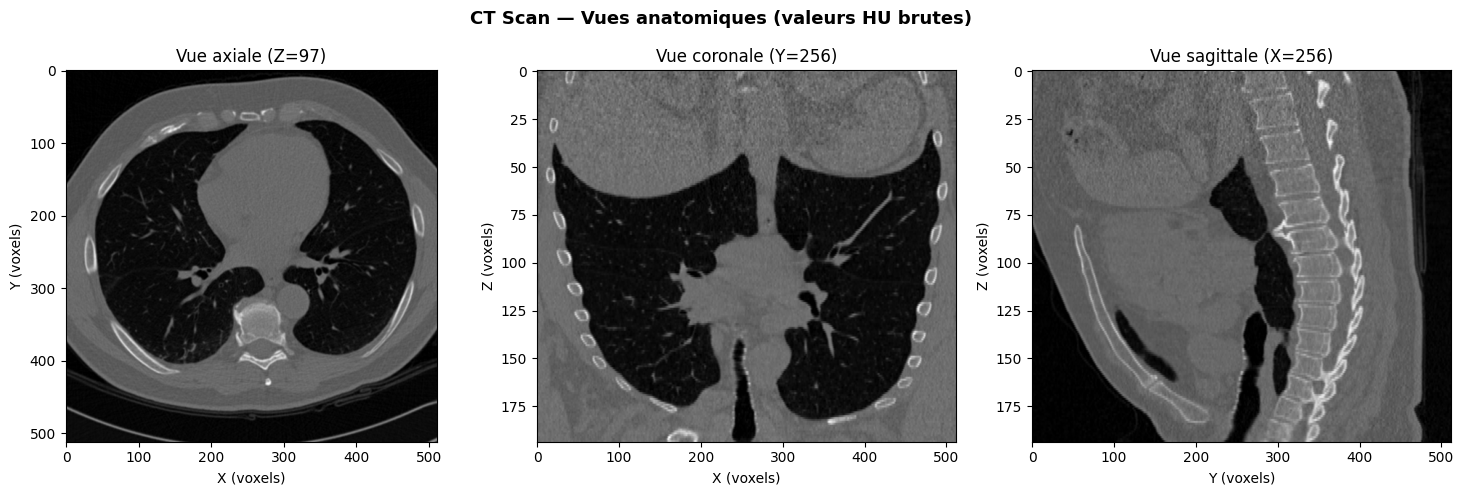

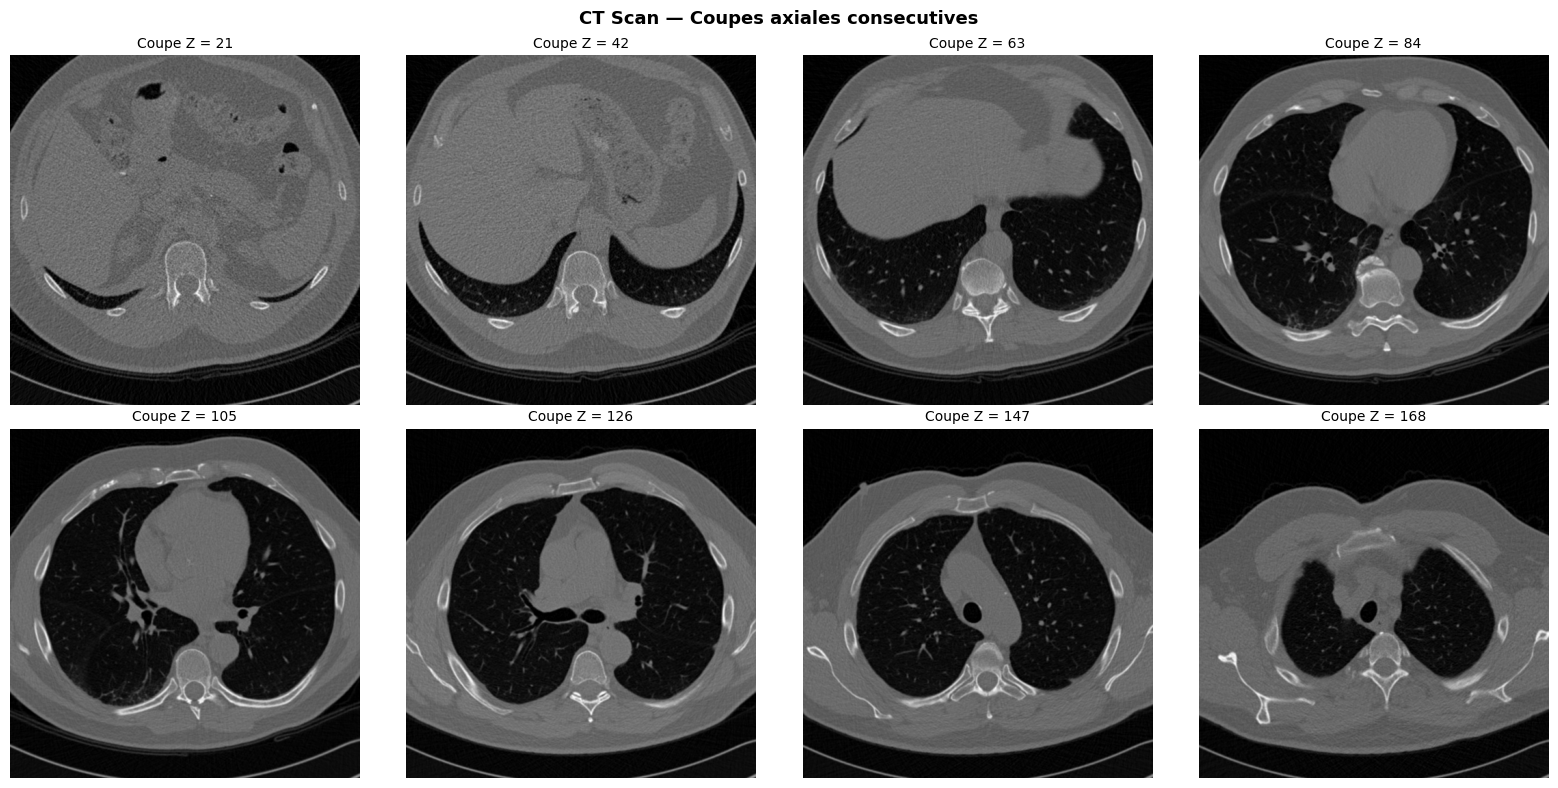

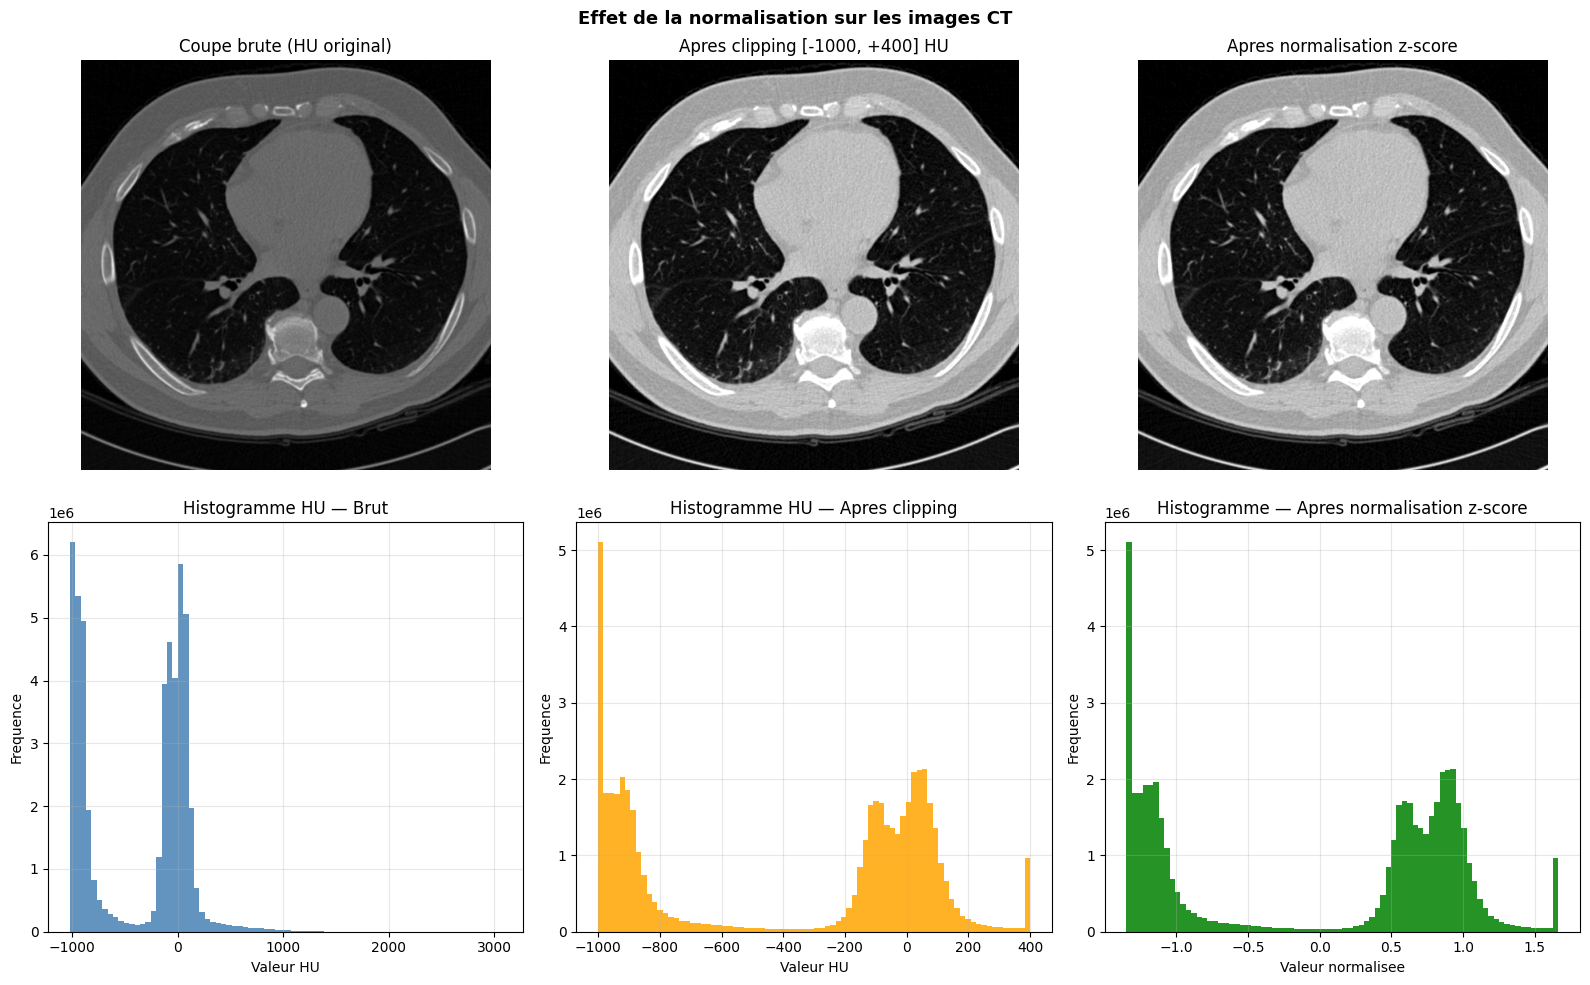

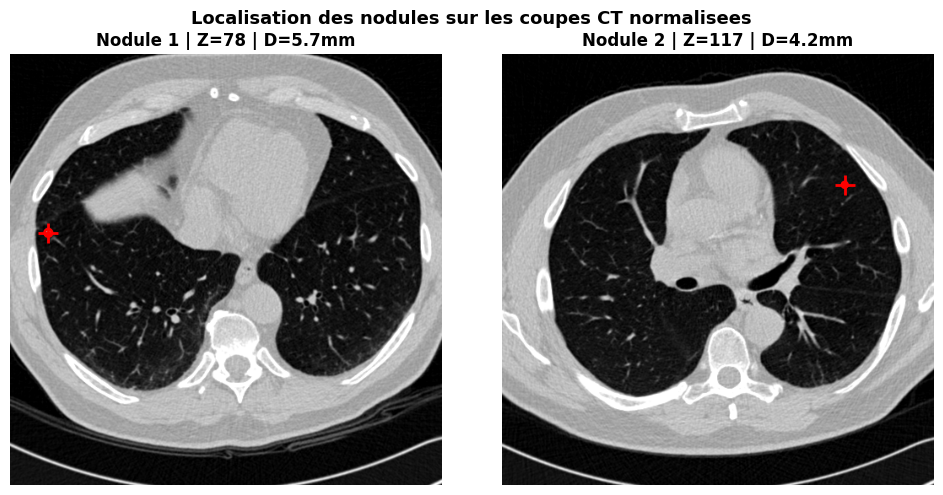

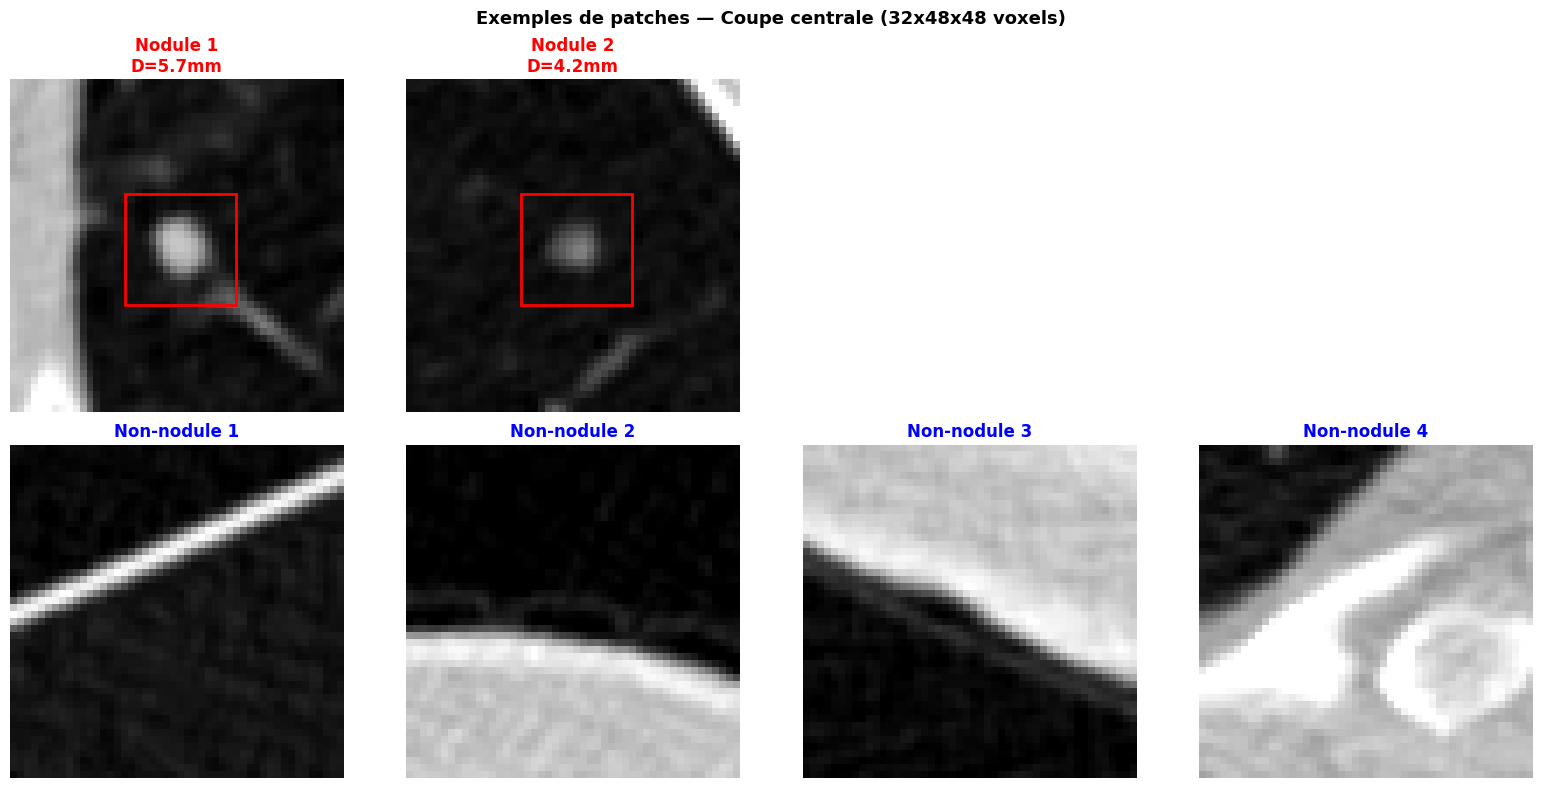

47

In [4]:
# ------------------------------------------------------------------ #
# CELLULE 4 — DATA REPRESENTATION
# ------------------------------------------------------------------ #

# Trouver un scan valide avec au moins 2 nodules pour la demo
demo_path    = None
demo_nodules = None

for path in list(nodules_by_scan.keys()):
    if len(nodules_by_scan[path]) >= 2:
        try:
            s, _, _ = load_ct_scan(path)
            if s.min() < -100:
                demo_path    = path
                demo_nodules = nodules_by_scan[path]
                del s
                break
        except:
            continue

scan_raw, origin, spacing = load_ct_scan(demo_path)
scan_clipped = clip_hu(scan_raw)
scan_norm    = normalize_hu(scan_clipped).astype(np.float32)

print("=" * 60)
print("        DATA REPRESENTATION")
print("=" * 60)
print(f"Scan : {os.path.basename(demo_path)}")
print(f"Shape         : {scan_raw.shape}  (Z, Y, X)")
print(f"Spacing       : {spacing} mm/voxel")
print(f"HU brut       : min={scan_raw.min():.0f}, max={scan_raw.max():.0f}, mean={scan_raw.mean():.1f}")
print(f"HU clipped    : min={scan_clipped.min():.0f}, max={scan_clipped.max():.0f}")
print(f"Normalise     : mean={scan_norm.mean():.4f}, std={scan_norm.std():.4f}")
print(f"Nodules       : {len(demo_nodules)}")

mid_z = scan_raw.shape[0] // 2
mid_y = scan_raw.shape[1] // 2
mid_x = scan_raw.shape[2] // 2

# ------------------------------------------------------------------ #
# FIGURE 1 — 3 VUES ANATOMIQUES
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(scan_raw[mid_z, :, :], cmap='gray')
axes[0].set_title(f'Vue axiale (Z={mid_z})')
axes[0].set_xlabel('X (voxels)'); axes[0].set_ylabel('Y (voxels)')

axes[1].imshow(scan_raw[:, mid_y, :], cmap='gray', aspect='auto')
axes[1].set_title(f'Vue coronale (Y={mid_y})')
axes[1].set_xlabel('X (voxels)'); axes[1].set_ylabel('Z (voxels)')

axes[2].imshow(scan_raw[:, :, mid_x], cmap='gray', aspect='auto')
axes[2].set_title(f'Vue sagittale (X={mid_x})')
axes[2].set_xlabel('Y (voxels)'); axes[2].set_ylabel('Z (voxels)')

plt.suptitle('CT Scan — Vues anatomiques (valeurs HU brutes)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/04a_vues_anatomiques.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ #
# FIGURE 2 — 8 COUPES AXIALES CONSECUTIVES
# ------------------------------------------------------------------ #
n_slices = 8
step     = scan_raw.shape[0] // (n_slices + 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(n_slices):
    z = step * (i + 1)
    axes[i].imshow(scan_raw[z, :, :], cmap='gray')
    axes[i].set_title(f'Coupe Z = {z}', fontsize=10)
    axes[i].axis('off')

plt.suptitle('CT Scan — Coupes axiales consecutives', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/04b_coupes_consecutives.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ #
# FIGURE 3 — AVANT / APRES NORMALISATION
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].imshow(scan_raw[mid_z, :, :], cmap='gray')
axes[0,0].set_title('Coupe brute (HU original)')
axes[0,0].axis('off')

axes[0,1].imshow(scan_clipped[mid_z, :, :], cmap='gray')
axes[0,1].set_title('Apres clipping [-1000, +400] HU')
axes[0,1].axis('off')

axes[0,2].imshow(scan_norm[mid_z, :, :], cmap='gray')
axes[0,2].set_title('Apres normalisation z-score')
axes[0,2].axis('off')

axes[1,0].hist(scan_raw.flatten(), bins=80, color='steelblue',
               edgecolor='none', alpha=0.85)
axes[1,0].set_title('Histogramme HU — Brut')
axes[1,0].set_xlabel('Valeur HU'); axes[1,0].set_ylabel('Frequence')
axes[1,0].grid(alpha=0.3)

axes[1,1].hist(scan_clipped.flatten(), bins=80, color='orange',
               edgecolor='none', alpha=0.85)
axes[1,1].set_title('Histogramme HU — Apres clipping')
axes[1,1].set_xlabel('Valeur HU'); axes[1,1].set_ylabel('Frequence')
axes[1,1].grid(alpha=0.3)

axes[1,2].hist(scan_norm.flatten(), bins=80, color='green',
               edgecolor='none', alpha=0.85)
axes[1,2].set_title('Histogramme — Apres normalisation z-score')
axes[1,2].set_xlabel('Valeur normalisee'); axes[1,2].set_ylabel('Frequence')
axes[1,2].grid(alpha=0.3)

plt.suptitle('Effet de la normalisation sur les images CT', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/04c_normalisation.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ #
# FIGURE 4 — COUPES AVEC NODULES ANNOTES
# ------------------------------------------------------------------ #
n_show = min(len(demo_nodules), 4)
fig, axes = plt.subplots(1, n_show, figsize=(5 * n_show, 5))
if n_show == 1:
    axes = [axes]

for i, nodule in enumerate(demo_nodules[:n_show]):
    center  = world_to_voxel(nodule['coord_world'], origin, spacing)
    z, y, x = center
    radius  = nodule['diameter'] / (2 * spacing[0])

    axes[i].imshow(scan_norm[z, :, :], cmap='gray')
    circle = plt.Circle((x, y), radius, color='red', fill=False, linewidth=2)
    axes[i].add_patch(circle)
    axes[i].plot(x, y, 'r+', markersize=14, markeredgewidth=2)
    axes[i].set_title(f'Nodule {i+1} | Z={z} | D={nodule["diameter"]:.1f}mm',
                       fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Localisation des nodules sur les coupes CT normalisees',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/04d_nodules_annotes.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ #
# FIGURE 5 — EXEMPLES PATCHES POSITIFS VS NEGATIFS
# ------------------------------------------------------------------ #
pos_demo = []
for nodule in demo_nodules:
    center = world_to_voxel(nodule['coord_world'], origin, spacing)
    z, y, x = center
    if (0 <= z < scan_norm.shape[0] and
        0 <= y < scan_norm.shape[1] and
        0 <= x < scan_norm.shape[2]):
        patch = extract_patch(scan_norm, center)
        pos_demo.append((patch, nodule['diameter']))

neg_demo      = []
nod_centers   = [world_to_voxel(n['coord_world'], origin, spacing) for n in demo_nodules]
attempts      = 0
while len(neg_demo) < 4 and attempts < 200:
    attempts += 1
    z = random.randint(16, scan_norm.shape[0] - 16)
    y = random.randint(24, scan_norm.shape[1] - 24)
    x = random.randint(24, scan_norm.shape[2] - 24)
    too_close = any(abs(z-cz) < 15 and abs(y-cy) < 15 and abs(x-cx) < 15
                    for cz, cy, cx in nod_centers)
    if not too_close:
        neg_demo.append(extract_patch(scan_norm, (z, y, x)))

n_pos    = min(len(pos_demo), 4)
n_neg    = min(len(neg_demo), 4)
n_cols   = max(n_pos, n_neg)
mid_cut  = 16

fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 8))

for i in range(n_cols):
    if i < n_pos:
        patch, diam = pos_demo[i]
        axes[0, i].imshow(patch[mid_cut, :, :], cmap='gray')
        axes[0, i].set_title(f'Nodule {i+1}\nD={diam:.1f}mm',
                              color='red', fontweight='bold')
        rect = plt.Rectangle((16, 16), 16, 16, linewidth=2,
                               edgecolor='red', facecolor='none')
        axes[0, i].add_patch(rect)
    else:
        axes[0, i].axis('off')

    if i < n_neg:
        axes[1, i].imshow(neg_demo[i][mid_cut, :, :], cmap='gray')
        axes[1, i].set_title(f'Non-nodule {i+1}', color='blue', fontweight='bold')
    else:
        axes[1, i].axis('off')

    axes[0, i].axis('off')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('POSITIF', fontsize=12, color='red', fontweight='bold')
axes[1, 0].set_ylabel('NEGATIF', fontsize=12, color='blue', fontweight='bold')

plt.suptitle('Exemples de patches — Coupe centrale (32x48x48 voxels)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/04e_exemples_patches.png', dpi=150, bbox_inches='tight')
plt.show()

del scan_raw, scan_clipped, scan_norm
gc.collect()


   EXTRACTION DES PATCHES — DATASET COMPLET
Scans a traiter  : 601
Patch size       : (32, 48, 48)
Negatifs/scan    : 4
Sauvegarde/batch : tous les 20 scans


  0%|          | 0/601 [00:00<?, ?it/s]

  Batch 00 | pos:   34 | neg:   88 | skipped so far: 38
  Batch 01 | pos:   23 | neg:   60 | skipped so far: 63
  Batch 02 | pos:   90 | neg:  172 | skipped so far: 120
  Batch 03 | pos:   44 | neg:   64 | skipped so far: 144
  Batch 04 | pos:   30 | neg:   48 | skipped so far: 172
  Batch 05 | pos:   17 | neg:   44 | skipped so far: 181
  Batch 06 | pos:   22 | neg:   48 | skipped so far: 189
  Batch 07 | pos:    9 | neg:   20 | skipped so far: 204
  Batch 08 | pos:   82 | neg:  140 | skipped so far: 249
  Batch 09 | pos:   79 | neg:  204 | skipped so far: 318
  Batch 10 | pos:   35 | neg:   80 | skipped so far: 359

Fusion des batches...
Scans traites    : 242 / 601
Scans ignores    : 359 (HU invalides ou erreurs)
Patches positifs : (465, 32, 48, 48)
Patches negatifs : (968, 32, 48, 48)
Ratio neg/pos    : 2.08


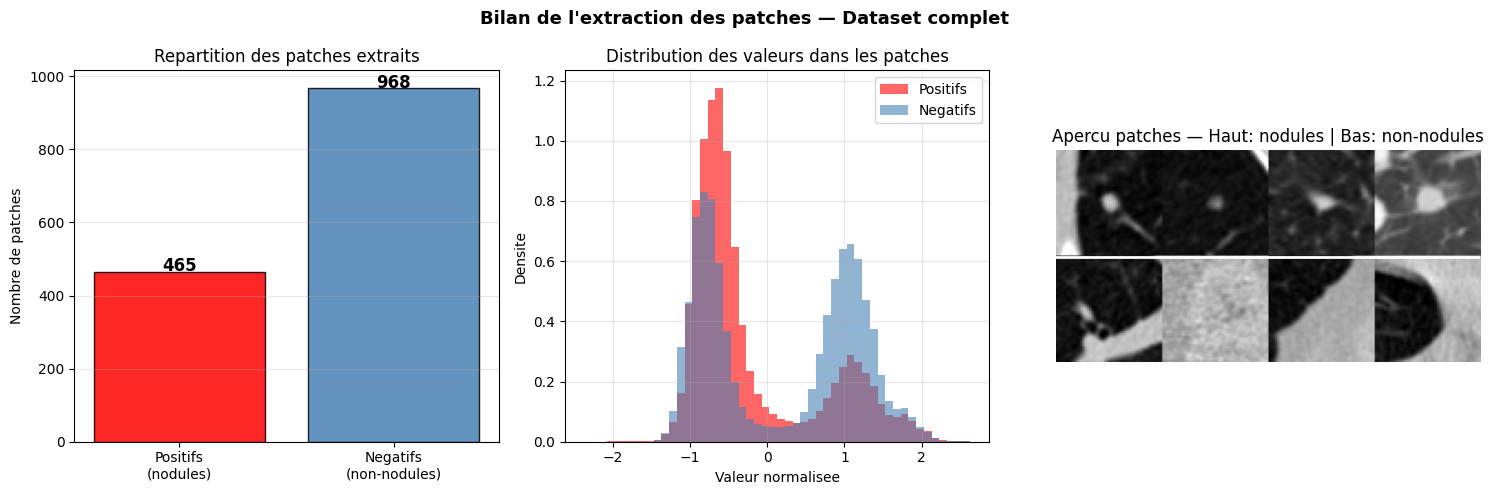

In [5]:
# ------------------------------------------------------------------ #
# CELLULE 5 — EXTRACTION COMPLETE SUR TOUT LE DATASET
# ------------------------------------------------------------------ #

PATCH_SIZE   = (32, 48, 48)
NEG_PER_SCAN = 4
SAVE_EVERY   = 20

scan_list     = list(nodules_by_scan.keys())  # TOUT le dataset
all_positives = []
all_negatives = []
batch_idx     = 0
skipped       = 0
total_pos     = 0
total_neg     = 0

print("=" * 60)
print("   EXTRACTION DES PATCHES — DATASET COMPLET")
print("=" * 60)
print(f"Scans a traiter  : {len(scan_list)}")
print(f"Patch size       : {PATCH_SIZE}")
print(f"Negatifs/scan    : {NEG_PER_SCAN}")
print(f"Sauvegarde/batch : tous les {SAVE_EVERY} scans")
print("=" * 60)

for i, mhd_path in enumerate(tqdm(scan_list)):
    try:
        scan_raw, origin, spacing = load_ct_scan(mhd_path)

        # Validation HU
        if scan_raw.min() > -100:
            skipped += 1
            del scan_raw
            gc.collect()
            continue

        scan_clipped = clip_hu(scan_raw)
        scan_norm    = normalize_hu(scan_clipped).astype(np.float32)
        del scan_raw, scan_clipped
        gc.collect()

        nodules = nodules_by_scan[mhd_path]

        # Patches positifs
        for nodule in nodules:
            center  = world_to_voxel(nodule['coord_world'], origin, spacing)
            z, y, x = center
            if (0 <= z < scan_norm.shape[0] and
                0 <= y < scan_norm.shape[1] and
                0 <= x < scan_norm.shape[2]):
                patch = extract_patch(scan_norm, center, PATCH_SIZE)
                all_positives.append(patch)

        # Patches negatifs
        nodule_centers = [world_to_voxel(n['coord_world'], origin, spacing)
                          for n in nodules]
        neg_count = 0
        attempts  = 0
        while neg_count < NEG_PER_SCAN and attempts < 100:
            attempts += 1
            z = random.randint(PATCH_SIZE[0], scan_norm.shape[0] - PATCH_SIZE[0])
            y = random.randint(PATCH_SIZE[1], scan_norm.shape[1] - PATCH_SIZE[1])
            x = random.randint(PATCH_SIZE[2], scan_norm.shape[2] - PATCH_SIZE[2])
            too_close = any(
                abs(z-cz) < 15 and abs(y-cy) < 15 and abs(x-cx) < 15
                for cz, cy, cx in nodule_centers
            )
            if not too_close:
                patch = extract_patch(scan_norm, (z, y, x), PATCH_SIZE)
                all_negatives.append(patch)
                neg_count += 1

        del scan_norm
        gc.collect()

    except Exception as e:
        print(f"Erreur : {os.path.basename(mhd_path)} : {e}")
        skipped += 1

    # Sauvegarde par batch
    if (i + 1) % SAVE_EVERY == 0 or (i + 1) == len(scan_list):
        if all_positives:
            np.save(f'/kaggle/working/pos_batch_{batch_idx}.npy',
                    np.array(all_positives, dtype=np.float32))
        if all_negatives:
            np.save(f'/kaggle/working/neg_batch_{batch_idx}.npy',
                    np.array(all_negatives, dtype=np.float32))
        total_pos += len(all_positives)
        total_neg += len(all_negatives)
        print(f"  Batch {batch_idx:02d} | pos: {len(all_positives):4d} | "
              f"neg: {len(all_negatives):4d} | skipped so far: {skipped}")
        all_positives = []
        all_negatives = []
        batch_idx += 1
        gc.collect()

# ------------------------------------------------------------------ #
# FUSION DES BATCHES
# ------------------------------------------------------------------ #
print("\nFusion des batches...")
pos_all = np.concatenate([np.load(f'/kaggle/working/pos_batch_{k}.npy')
                           for k in range(batch_idx)], axis=0)
neg_all = np.concatenate([np.load(f'/kaggle/working/neg_batch_{k}.npy')
                           for k in range(batch_idx)], axis=0)

np.save('/kaggle/working/patches_positifs.npy', pos_all)
np.save('/kaggle/working/patches_negatifs.npy', neg_all)

print("=" * 60)
print(f"Scans traites    : {len(scan_list) - skipped} / {len(scan_list)}")
print(f"Scans ignores    : {skipped} (HU invalides ou erreurs)")
print(f"Patches positifs : {pos_all.shape}")
print(f"Patches negatifs : {neg_all.shape}")
print(f"Ratio neg/pos    : {len(neg_all)/len(pos_all):.2f}")

# ------------------------------------------------------------------ #
# BILAN VISUEL
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Repartition des classes
axes[0].bar(['Positifs\n(nodules)', 'Negatifs\n(non-nodules)'],
            [len(pos_all), len(neg_all)],
            color=['red', 'steelblue'], edgecolor='black', alpha=0.85)
for i, v in enumerate([len(pos_all), len(neg_all)]):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=12)
axes[0].set_title('Repartition des patches extraits')
axes[0].set_ylabel('Nombre de patches')
axes[0].grid(axis='y', alpha=0.3)

# Distribution des valeurs
axes[1].hist(pos_all.flatten(), bins=50, color='red',
             alpha=0.6, label='Positifs', density=True)
axes[1].hist(neg_all.flatten(), bins=50, color='steelblue',
             alpha=0.6, label='Negatifs', density=True)
axes[1].set_title('Distribution des valeurs dans les patches')
axes[1].set_xlabel('Valeur normalisee')
axes[1].set_ylabel('Densite')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Grille patches positifs vs negatifs
mid_cut = PATCH_SIZE[0] // 2
n_ex    = 4
grid    = np.zeros((2 * 48, n_ex * 48))
for j in range(n_ex):
    if j < len(pos_all):
        grid[:48,   j*48:(j+1)*48] = pos_all[j][mid_cut]
    if j < len(neg_all):
        grid[48:96, j*48:(j+1)*48] = neg_all[j][mid_cut]
axes[2].imshow(grid, cmap='gray')
axes[2].axhline(48, color='white', linewidth=2)
axes[2].set_title('Apercu patches — Haut: nodules | Bas: non-nodules')
axes[2].axis('off')

plt.suptitle('Bilan de l\'extraction des patches — Dataset complet',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/05_bilan_extraction.png', dpi=150, bbox_inches='tight')
plt.show()


=== 1. ANALYSE DU DÉSÉQUILIBRE REEL ===
• Patches positifs réels extraits : 465
• Patches négatifs réels extraits : 968
-> Écart à combler par augmentation géométrique : +503 patches.

=== 2. APPLICATION DU FLIP HORIZONTAL SUR L'AXE X ===
 Classe positive rééquilibrée ! Nouvelle taille : (968, 32, 48, 48) (Attendu: 968)
 Classe négative (inchangée)    ! Taille        : (968, 32, 48, 48)

=== 3. VISUALISATION COMPARATIVE : ORIGINAL VS AUGMENTÉ ===


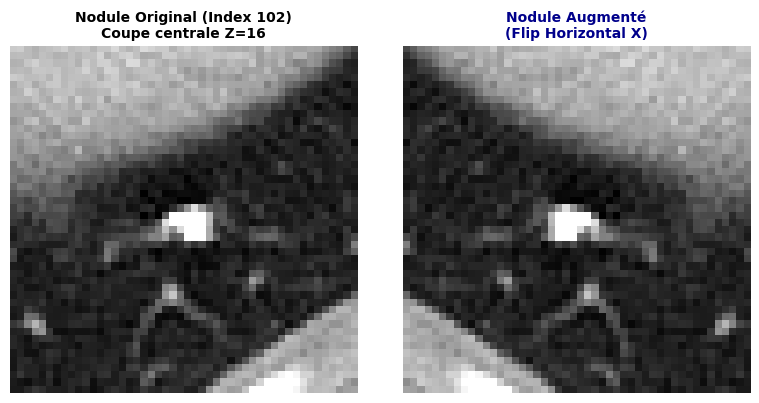

In [6]:
# ==================================================================== #
# CELLULE 6 : STRATÉGIE D'ÉQUILIBRAGE PARFAIT A 50/50 (AUGMENTATION)
# ==================================================================== #
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle

print("=== 1. ANALYSE DU DÉSÉQUILIBRE REEL ===")
pos_all = np.load('/kaggle/working/patches_positifs.npy')
neg_all = np.load('/kaggle/working/patches_negatifs.npy')

n_pos_initial = len(pos_all)
n_neg_total = len(neg_all)

print(f"• Patches positifs réels extraits : {n_pos_initial}")
print(f"• Patches négatifs réels extraits : {n_neg_total}")

# Calcul du déficit exact pour obtenir un ratio strict de 50/50
n_manquant = n_neg_total - n_pos_initial
print(f"-> Écart à combler par augmentation géométrique : +{n_manquant} patches.")

# --- AUGMENTATION GÉOMÉTRIQUE CIBLÉE ---
print("\n=== 2. APPLICATION DU FLIP HORIZONTAL SUR L'AXE X ===")
np.random.seed(42)
idx_choisis = np.random.choice(n_pos_initial, size=n_manquant, replace=True)
pos_a_transformer = pos_all[idx_choisis].copy()

# Application du retournement sur l'axe X (Axe 3 du tenseur 3D: [N_patches, Z, Y, X])
pos_augmentes = np.flip(pos_a_transformer, axis=3)

# Fusion pour obtenir la classe positive parfaitement équilibrée (465 + 503 = 968)
pos_equilibres = np.concatenate([pos_all, pos_augmentes], axis=0)

print(f" Classe positive rééquilibrée ! Nouvelle taille : {pos_equilibres.shape} (Attendu: {n_neg_total})")
print(f" Classe négative (inchangée)    ! Taille        : {neg_all.shape}")

# --- VISUALISATION DE CONTRÔLE DE L'AUGMENTATION ---
print("\n=== 3. VISUALISATION COMPARATIVE : ORIGINAL VS AUGMENTÉ ===")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
mid_cut = pos_all.shape[1] // 2  # Coupe centrale Z (16)

# Affichage du premier nodule sélectionné pour l'augmentation
axes[0].imshow(pos_all[idx_choisis[0]][mid_cut], cmap='gray')
axes[0].set_title(f"Nodule Original (Index {idx_choisis[0]})\nCoupe centrale Z=16", fontsize=10, fontweight='bold')
axes[0].axis('off')

# Affichage de sa version augmentée (Flip horizontal)
axes[1].imshow(pos_augmentes[0][mid_cut], cmap='gray')
axes[1].set_title("Nodule Augmenté\n(Flip Horizontal X)", fontsize=10, fontweight='bold', color='darkblue')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Sauvegarde temporaire des volumes équilibrés pour préserver la RAM
np.save('/kaggle/working/patches_positifs_equilibres.npy', pos_equilibres)

Model: "LUNA16_CNN3D_Extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ CT_Scan_Input (InputLayer)      │ (None, 32, 48, 48, 1)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3D_B1 (Conv3D)              │ (None, 32, 48, 48, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 48, 48, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 24, 24, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 24, 24, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3D_B2 (Conv3D)              │ (None, 16, 24, 24, 64) │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 24, 24, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 12, 12, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 12, 12, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3D_B3 (Conv3D)              │ (None, 8, 12, 12, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 12, 12, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_feature_extraction_layer    │ (None, 128)            │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Classification_Output (Dense)   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303,297 (1.16 MB)

 Trainable params: 302,849 (1.16 MB)

 Non-trainable params: 448 (1.75 KB)


--- Étape A : Entraînement de l'Extracteur CNN 3D ---
Epoch 1/40


I0000 00:00:1779214611.106495     154 service.cc:152] XLA service 0x21331320 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779214611.106568     154 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1779214611.106577     154 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


 2/85 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.3594 - auc: 0.3296 - loss: 0.7727 - precision: 0.4330 - recall: 0.3509  

I0000 00:00:1779214617.702369     154 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


85/85 ━━━━━━━━━━━━━━━━━━━━ 24s 170ms/step - accuracy: 0.6133 - auc: 0.6943 - loss: 0.6016 - precision: 0.6071 - recall: 0.6492 - val_accuracy: 0.4983 - val_auc: 0.7410 - val_loss: 1.3439 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7653 - auc: 0.8351 - loss: 0.4861 - precision: 0.7343 - recall: 0.8133 - val_accuracy: 0.4983 - val_auc: 0.5101 - val_loss: 3.5906 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.7765 - auc: 0.8437 - loss: 0.4699 - precision: 0.7274 - recall: 0.8893 - val_accuracy: 0.4983 - val_auc: 0.7077 - val_loss: 2.7665 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.7881 - auc: 0.8485 - loss: 0.4685 - precision: 0.7643 - recall: 0.8458 - val_accuracy: 0.5361 - val_auc: 0.6915 - val_loss: 2

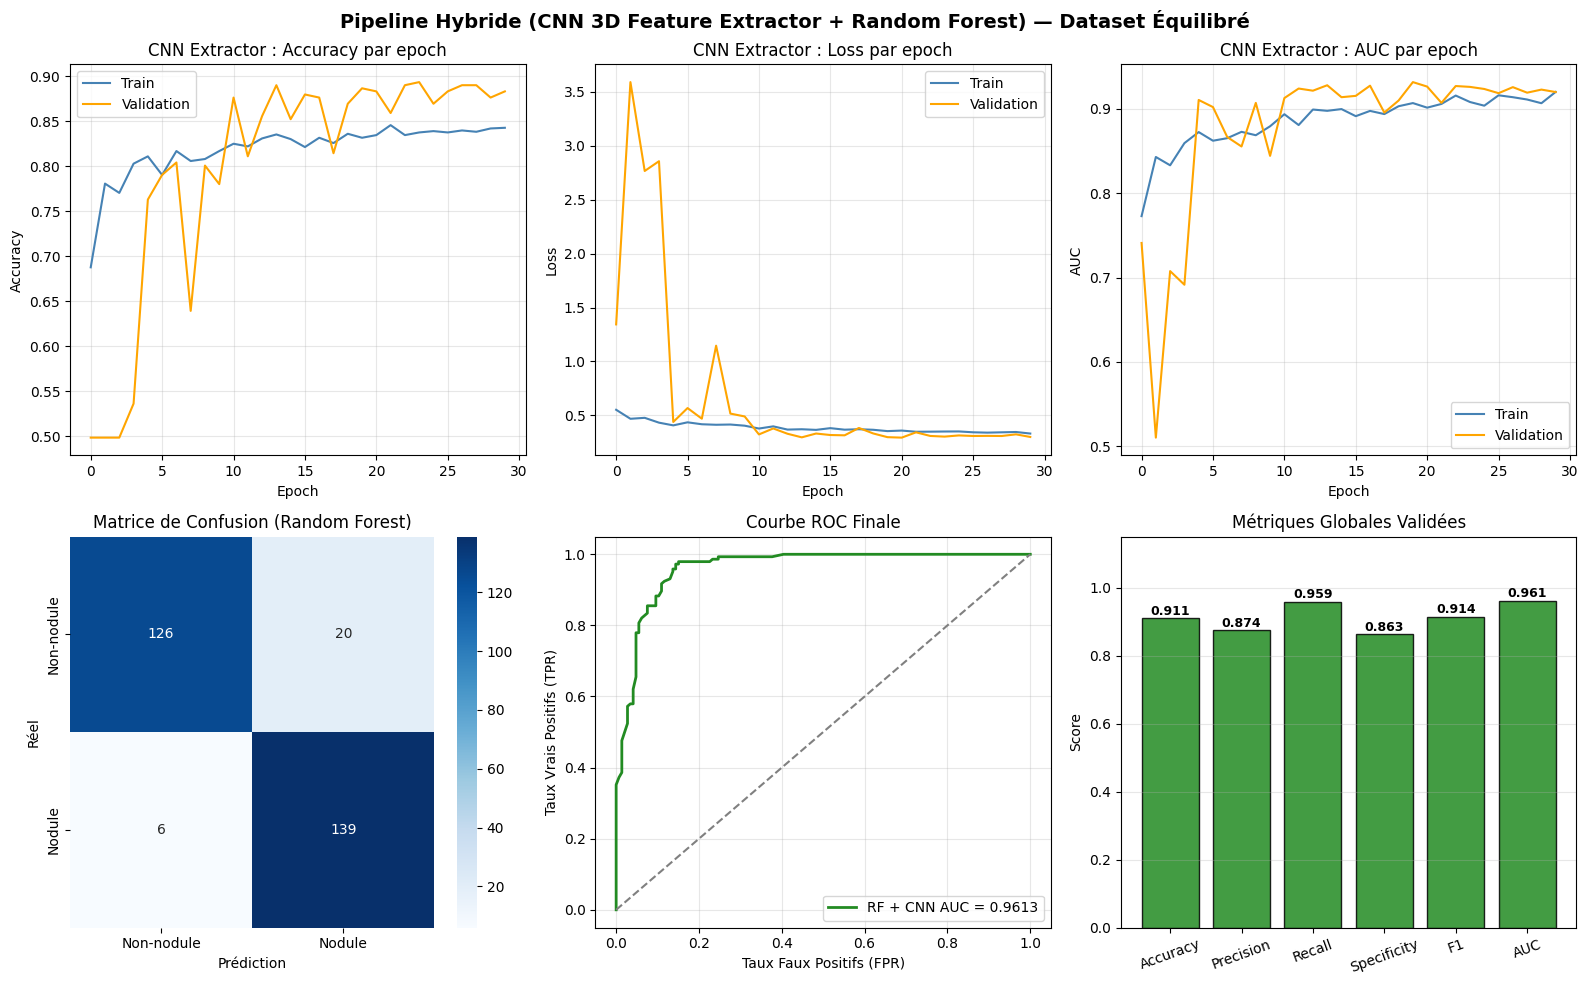

In [9]:
# ------------------------------------------------------------------ #
#PIPELINE HYBRIDE : CNN 3D FEATURE EXTRACTION & RANDOM FOREST
# ------------------------------------------------------------------ #
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

# ==================================================================== #
# 1. ARCHITECTURE DU MODÈLE (FUNCTIONAL API POUR LE FEATURE EXTRACTION)
# ==================================================================== #
def build_cnn3d_extractor(input_shape=(32, 48, 48, 1)):
    inputs = Input(shape=input_shape, name="CT_Scan_Input")
    
    # Bloc 1
    x = layers.Conv3D(32, (3,3,3), activation='relu', padding='same', name="Conv3D_B1")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling3D((2,2,2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloc 2
    x = layers.Conv3D(64, (3,3,3), activation='relu', padding='same', name="Conv3D_B2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling3D((2,2,2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloc 3
    x = layers.Conv3D(128, (3,3,3), activation='relu', padding='same', name="Conv3D_B3")(x)
    x = layers.BatchNormalization()(x)
    
    # COUCHE STRATÉGIQUE : Extraction du vecteur de caractéristiques (Features)
    # On condense l'espace 3D en un vecteur discriminant de 128 dimensions
    features = layers.GlobalAveragePooling3D(name="cnn_feature_extraction_layer")(x)
    features = layers.Dropout(0.5)(features)

    # Tête de classification temporaire (Nécessaire pour pré-entraîner l'extracteur)
    dense1 = layers.Dense(128, activation='relu')(features)
    dense2 = layers.Dense(64, activation='relu')(dense1)
    outputs = layers.Dense(1, activation='sigmoid', name="Classification_Output")(dense2)
    
    # Création du modèle global
    model = models.Model(inputs=inputs, outputs=outputs, name="LUNA16_CNN3D_Extractor")
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), 
                 tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')]
    )
    return model

# Initialisation du modèle
cnn_model = build_cnn3d_extractor()
cnn_model.summary()

# ==================================================================== #
# 2. PRÉ-ENTRAÎNEMENT DU CNN 3D (APPRENTISSAGE DES FEATURES)
# ==================================================================== #
callbacks_cnn = [
    EarlyStopping(monitor='val_auc', patience=10, restore_best_weights=True, mode='max', verbose=1),
    ModelCheckpoint('/kaggle/working/best_cnn3d.keras', monitor='val_auc', save_best_only=True, mode='max', verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n--- Étape A : Entraînement de l'Extracteur CNN 3D ---")
start_cnn = time.time()
history_cnn = cnn_model.fit(
    X_train, y_train,
    batch_size=16,
    epochs=40,
    validation_data=(X_val, y_val),
    callbacks=callbacks_cnn,
    verbose=1
)
cnn_training_time = time.time() - start_cnn
print(f"Temps d'entraînement du CNN : {cnn_training_time:.1f} secondes")

# Chargement des meilleurs poids optimisés
cnn_model.load_weights('/kaggle/working/best_cnn3d.keras')

# ==================================================================== #
# 3. EXTRACTION DES FEATURES ET CLASSIFICATION PAR RANDOM FOREST
# ==================================================================== #
print("\n--- Étape B : Extraction des Caractéristiques (Feature Extraction) ---")
# On crée un modèle intermédiaire qui s'arrête pile à la couche GlobalAveragePooling3D
feature_extractor = models.Model(inputs=cnn_model.input, outputs=cnn_model.get_layer("cnn_feature_extraction_layer").output)

# Extraction des caractéristiques vectorielles (128 features par patch 3D)
X_train_features = feature_extractor.predict(X_train, verbose=0)
X_test_features = feature_extractor.predict(X_test, verbose=0)

print(f"• Taille des features d'entraînement extraites : {X_train_features.shape} -> (N_Patches, 128 Features)")
print(f"• Taille des features de test extraites         : {X_test_features.shape}")

print("\n--- Étape C : Entraînement du Classifieur Random Forest ---")
start_rf = time.time()
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_classifier.fit(X_train_features, y_train)
rf_training_time = time.time() - start_rf

# ==================================================================== #
# 4. ÉVALUATION DU PIPELINE HYBRIDE FINAL (CNN + RF)
# ==================================================================== #
# Prédictions finales via le Random Forest branché sur les features du CNN
y_pred_proba_rf = rf_classifier.predict_proba(X_test_features)[:, 1]
y_pred_rf = rf_classifier.predict(X_test_features)

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm_rf.ravel()

precision_rf = tp / (tp + fp + 1e-8)
recall_rf    = tp / (tp + fn + 1e-8)
f1_rf        = 2 * precision_rf * recall_rf / (precision_rf + recall_rf + 1e-8)
specificity_rf = tn / (tn + fp + 1e-8)
accuracy_rf  = (tp + tn) / (tp + tn + fp + fn)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
auc_rf        = auc(fpr_rf, tpr_rf)

pipeline_metrics = {
    'accuracy'   : accuracy_rf,
    'precision'  : precision_rf,
    'recall'     : recall_rf,
    'specificity': specificity_rf,
    'f1'         : f1_rf,
    'auc'        : auc_rf,
    'time_sec'   : cnn_training_time + rf_training_time
}

print("\n=========================================")
print("RÉSULTATS DU PIPELINE : CNN 3D + RANDOM FOREST")
print("=========================================")
for k, v in pipeline_metrics.items():
    print(f"  {k:<14} : {v:.4f}")
print()
print(classification_report(y_test, y_pred_rf, target_names=['Non-nodule', 'Nodule']))

# ==================================================================== #
# 5. VISUALISATIONS COMPLÈTES ET RAPPORT GRAPHIQUE
# ==================================================================== #
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Graphique 1 : Accuracy du CNN (Phase d'apprentissage des descripteurs)
axes[0,0].plot(history_cnn.history['accuracy'], label='Train', color='steelblue')
axes[0,0].plot(history_cnn.history['val_accuracy'], label='Validation', color='orange')
axes[0,0].set_title('CNN Extractor : Accuracy par epoch')
axes[0,0].set_xlabel('Epoch'); axes[0,0].set_ylabel('Accuracy')
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

# Graphique 2 : Loss du CNN
axes[0,1].plot(history_cnn.history['loss'], label='Train', color='steelblue')
axes[0,1].plot(history_cnn.history['val_loss'], label='Validation', color='orange')
axes[0,1].set_title('CNN Extractor : Loss par epoch')
axes[0,1].set_xlabel('Epoch'); axes[0,1].set_ylabel('Loss')
axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# Graphique 3 : AUC du CNN
axes[0,2].plot(history_cnn.history['auc'], label='Train', color='steelblue')
axes[0,2].plot(history_cnn.history['val_auc'], label='Validation', color='orange')
axes[0,2].set_title('CNN Extractor : AUC par epoch')
axes[0,2].set_xlabel('Epoch'); axes[0,2].set_ylabel('AUC')
axes[0,2].legend(); axes[0,2].grid(alpha=0.3)

# Graphique 4 : Matrice de Confusion du Random Forest Final
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-nodule', 'Nodule'],
            yticklabels=['Non-nodule', 'Nodule'], ax=axes[1,0])
axes[1,0].set_title('Matrice de Confusion (Random Forest)')
axes[1,0].set_xlabel('Prédiction'); axes[1,0].set_ylabel('Réel')

# Graphique 5 : Courbe ROC Finale du Random Forest
axes[1,1].plot(fpr_rf, tpr_rf, color='forestgreen', lw=2, label=f'RF + CNN AUC = {auc_rf:.4f}')
axes[1,1].plot([0,1], [0,1], '--', color='gray')
axes[1,1].set_title('Courbe ROC Finale')
axes[1,1].set_xlabel('Taux Faux Positifs (FPR)')
axes[1,1].set_ylabel('Taux Vrais Positifs (TPR)')
axes[1,1].legend(); axes[1,1].grid(alpha=0.3)

# Graphique 6 : Métriques Globales Comparatives
m_names = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']
m_vals  = [pipeline_metrics[k] for k in ['accuracy', 'precision', 'recall', 'specificity', 'f1', 'auc']]
bars = axes[1,2].bar(m_names, m_vals, color='forestgreen', edgecolor='black', alpha=0.85)
axes[1,2].set_ylim(0, 1.15)
axes[1,2].set_title('Métriques Globales Validées')
axes[1,2].set_ylabel('Score')
axes[1,2].tick_params(axis='x', rotation=20)
for bar, v in zip(bars, m_vals):
    axes[1,2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[1,2].grid(axis='y', alpha=0.3)

plt.suptitle('Pipeline Hybride (CNN 3D Feature Extractor + Random Forest) — Dataset Équilibré', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/07_resultats_pipeline_hybride.png', dpi=150, bbox_inches='tight')
plt.show()

=== 1. PREPARATION U-NET ===
X_train_2d : (1354, 48, 48, 1)
M_train    : (1354, 48, 48, 1)
Positifs train : 677 | masques non-vides : 677

=== 2. COMPILATION DU MODELE U-NET TRANSFER LEARNING ===


Model: "LUNA16_UNet_VGG16_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 48, 48, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gris_vers_RVB       │ (None, 48, 48, 3) │          6 │ input_layer_1[0]… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ [(None, 48, 48,   │  1,735,488 │ Gris_vers_RVB[0]… │
│ (Functional)        │ 64), (None, 24,   │            │                   │
│                     │ 24, 128), (None,  │            │                   │
│                     │ 12, 12, 256)]     │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 24, 24,    │          0 │ functional_1[0][… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 24,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 24, 24,    │          0 │ concatenate[0][0] │
│                     │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 24, 24,    │    221,248 │ dropout_9[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 48, 48,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 128)              │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 48, 48,    │          0 │ concatenate_1[0]… │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 48, 48,    │     36,896 │ dropout_10[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Mask_Output         │ (None, 48, 48, 1) │         33 │ batch_normalizat… │
│ (Conv2D)            │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,994,055 (7.61 MB)

 Trainable params: 258,375 (1009.28 KB)

 Non-trainable params: 1,735,680 (6.62 MB)


=== 3. ENTRAINEMENT U-NET ===
Epoch 1/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - accuracy: 0.7861 - auc: 0.8665 - loss: 0.5747 - precision: 0.1693 - recall: 0.7892 - val_accuracy: 0.9783 - val_auc: 0.9769 - val_loss: 0.1075 - val_precision: 0.8898 - val_recall: 0.5643 - learning_rate: 0.0010
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9767 - auc: 0.9595 - loss: 0.2279 - precision: 0.7466 - recall: 0.7022 - val_accuracy: 0.9793 - val_auc: 0.9858 - val_loss: 0.1013 - val_precision: 0.8982 - val_recall: 0.5837 - learning_rate: 0.0010
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9808 - auc: 0.9775 - loss: 0.1194 - precision: 0.8450 - recall: 0.6890 - val_accuracy: 0.9821 - val_auc: 0.9875 - val_loss: 0.1065 - val_precision: 0.8539 - val_recall: 0.7025 - learning_rate: 0.0010
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9813 - auc: 0.9848 - loss: 0.0885 - precision: 0.8551 - recall: 0.6908 - val_accuracy: 0.9813 - val_auc: 0.

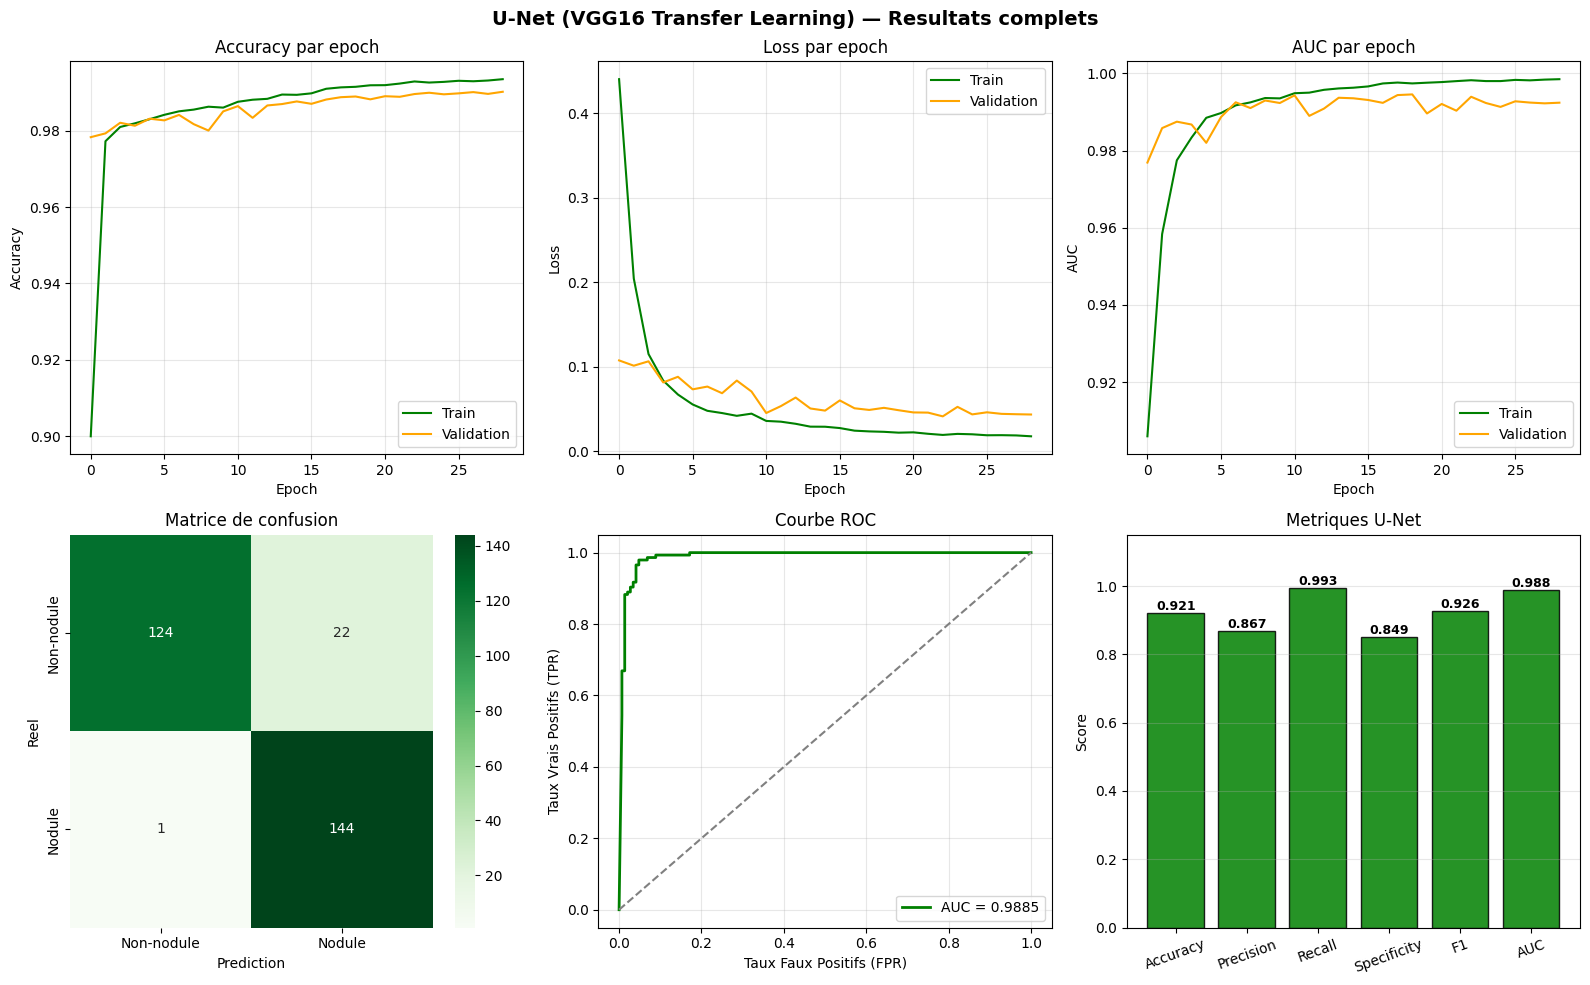

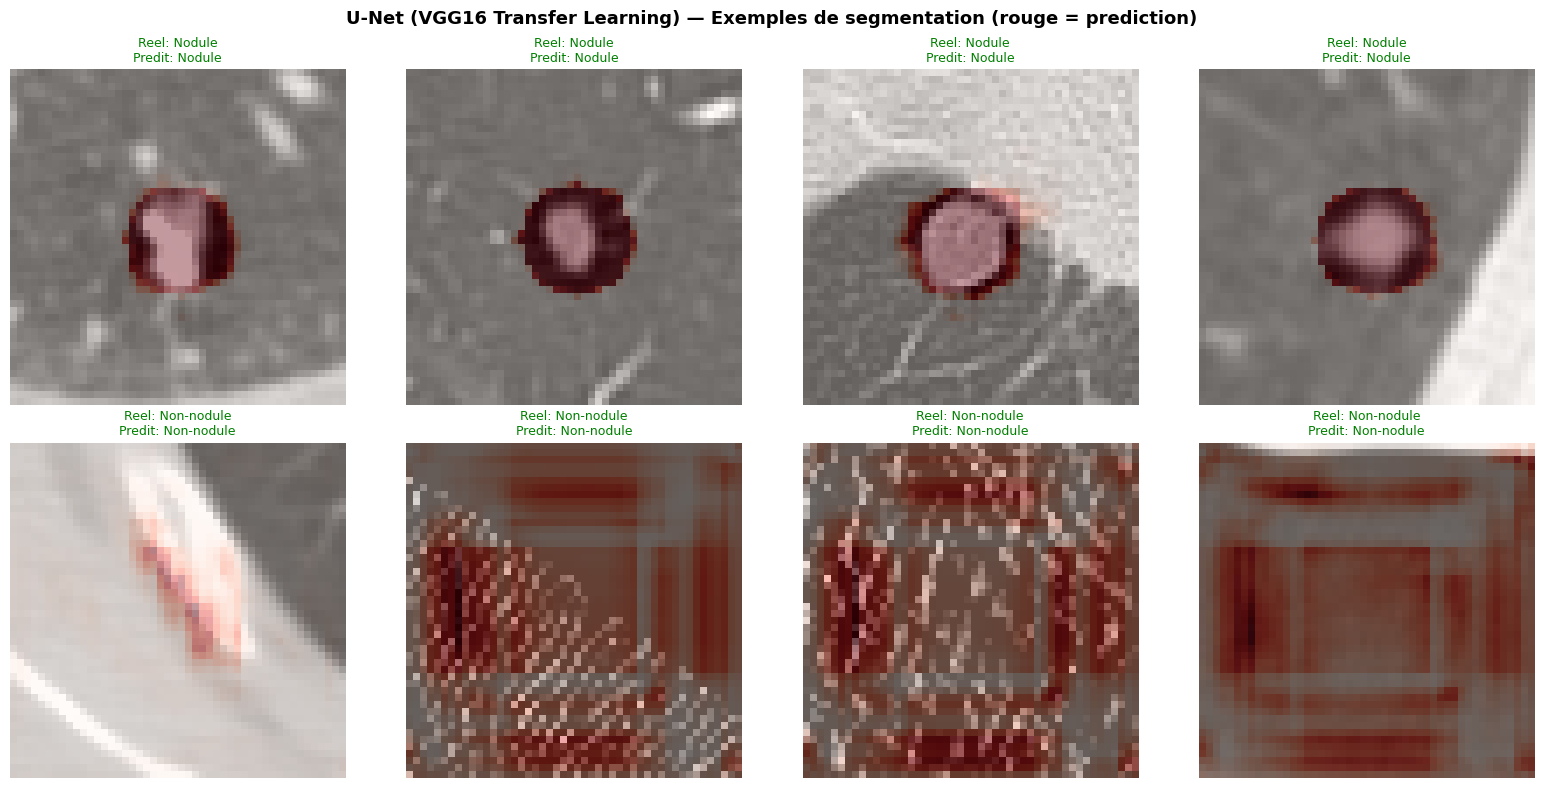

26574

In [11]:
# ------------------------------------------------------------------ #
#  U-NET AVEC TRANSFER LEARNING (VGG16 BACKBONE) 
# ------------------------------------------------------------------ #
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
import gc

# ------------------------------------------------------------------ #
# PREPARATION DES DONNEES 2D + MASQUES DE SEGMENTATION
# ------------------------------------------------------------------ #
def create_circular_mask(h, w, radius=8):
    cy, cx = h // 2, w // 2
    Y, X   = np.ogrid[:h, :w]
    mask   = ((X - cx)**2 + (Y - cy)**2 <= radius**2).astype(np.float32)
    return mask

mid      = X_train.shape[1] // 2  # coupe centrale
H, W     = X_train.shape[2], X_train.shape[3]
circle   = create_circular_mask(H, W, radius=8)

# Coupes 2D
X_train_2d = X_train[:, mid, :, :, :]  # (N, 48, 48, 1)
X_val_2d   = X_val[:,   mid, :, :, :]
X_test_2d  = X_test[:,  mid, :, :, :]

# Masques : cercle pour positifs, zeros pour negatifs
M_train = np.array([circle[..., np.newaxis] if y == 1
                    else np.zeros((H, W, 1), dtype=np.float32)
                    for y in y_train])
M_val   = np.array([circle[..., np.newaxis] if y == 1
                    else np.zeros((H, W, 1), dtype=np.float32)
                    for y in y_val])
M_test  = np.array([circle[..., np.newaxis] if y == 1
                    else np.zeros((H, W, 1), dtype=np.float32)
                    for y in y_test])

print("=== 1. PREPARATION U-NET ===")
print(f"X_train_2d : {X_train_2d.shape}")
print(f"M_train    : {M_train.shape}")
print(f"Positifs train : {int(y_train.sum())} | masques non-vides : {int((M_train.max(axis=(1,2,3)) > 0).sum())}")

# ------------------------------------------------------------------ #
# ARCHITECTURE U-NET 2D AVEC TRANSFER LEARNING (VGG16)
# ------------------------------------------------------------------ #
def build_unet_vgg16(input_shape=(48, 48, 1)):
    inputs = Input(input_shape)
    
    # 1. Conversion 1 canal (Gris) vers 3 canaux (RVB)
    x = layers.Conv2D(3, (1, 1), padding='same', name="Gris_vers_RVB")(inputs)

    # 2. Chargement de VGG16 avec son entrée standard (48, 48, 3) pour éviter le bug de poids
    vgg = VGG16(include_top=False, weights='imagenet', input_shape=(input_shape[0], input_shape[1], 3))
    
    # Congélation des poids de VGG16
    for layer in vgg.layers:
        layer.trainable = False

    # 3. On applique le réseau VGG16 sur notre tenseur converti 'x' via l'API fonctionnelle
    vgg_output = vgg(x)

    # 4. Récupération des sorties intermédiaires pour les Skip Connections
    # On va chercher directement dans le sous-modèle VGG16
    s1 = vgg.get_layer("block1_conv2").output  
    s2 = vgg.get_layer("block2_conv2").output  
    bn = vgg.get_layer("block3_conv3").output  
    
    # On reconstruit l'arbre fonctionnel lié à notre entrée réelle
    encoder_model = models.Model(inputs=vgg.input, outputs=[s1, s2, bn])
    s1_features, s2_features, bn_features = encoder_model(x)

    # 5. Décodeur (Reconstruction de la résolution spatiale)
    # Premier bloc de remontée (12x12 -> 24x24)
    u1 = layers.UpSampling2D((2, 2))(bn_features)
    u1 = layers.Concatenate()([u1, s2_features])
    u1 = layers.Dropout(0.2)(u1)
    x1 = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(u1)
    x1 = layers.BatchNormalization()(x1)

    # Deuxième bloc de remontée (24x24 -> 48x48)
    u2 = layers.UpSampling2D((2, 2))(x1)
    u2 = layers.Concatenate()([u2, s1_features])
    u2 = layers.Dropout(0.2)(u2)
    x2 = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(u2)
    x2 = layers.BatchNormalization()(x2)

    # Couche finale de décision pixel par pixel
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid', name="Mask_Output")(x2)

    model = models.Model(inputs, outputs, name="LUNA16_UNet_VGG16_Transfer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
            tf.keras.metrics.AUC(name='auc')
        ]
    )
    return model

print("\n=== 2. COMPILATION DU MODELE U-NET TRANSFER LEARNING ===")
unet_model = build_unet_vgg16()
unet_model.summary()

# ------------------------------------------------------------------ #
# ENTRAINEMENT
# ------------------------------------------------------------------ #
callbacks_unet = [
    EarlyStopping(monitor='val_auc', patience=10,
                  restore_best_weights=True, mode='max', verbose=1),
    ModelCheckpoint('/kaggle/working/best_unet.keras',
                    monitor='val_auc', save_best_only=True, mode='max', verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-6, verbose=1)
]

print("\n=== 3. ENTRAINEMENT U-NET ===")
start_unet = time.time()
history_unet = unet_model.fit(
    X_train_2d, M_train,
    batch_size=16,
    epochs=50,
    validation_data=(X_val_2d, M_val),
    callbacks=callbacks_unet,
    verbose=1
)
unet_training_time = time.time() - start_unet
print(f"\nTemps d'entrainement : {unet_training_time:.1f} secondes")

# ------------------------------------------------------------------ #
# EVALUATION
# ------------------------------------------------------------------ #
unet_model.load_weights('/kaggle/working/best_unet.keras')
pred_masks = unet_model.predict(X_test_2d, verbose=0)  # (N, 48, 48, 1)

# Classification : score = valeur max predite dans le patch
y_pred_proba_unet = pred_masks.max(axis=(1, 2, 3))
y_pred_unet       = (y_pred_proba_unet > 0.5).astype(int)

cm_unet          = confusion_matrix(y_test, y_pred_unet)
tn, fp, fn, tp   = cm_unet.ravel()

precision_unet   = tp / (tp + fp + 1e-8)
recall_unet      = tp / (tp + fn + 1e-8)
f1_unet          = 2 * precision_unet * recall_unet / (precision_unet + recall_unet + 1e-8)
specificity_unet = tn / (tn + fp + 1e-8)
accuracy_unet    = (tp + tn) / (tp + tn + fp + fn)
fpr_unet, tpr_unet, _ = roc_curve(y_test, y_pred_proba_unet)
auc_unet         = auc(fpr_unet, tpr_unet)

unet_metrics = {
    'accuracy'   : accuracy_unet,
    'precision'  : precision_unet,
    'recall'     : recall_unet,
    'specificity': specificity_unet,
    'f1'         : f1_unet,
    'auc'        : auc_unet,
    'time_sec'   : unet_training_time
}

print("\nResultats U-Net (Transfer Learning)")
print("=" * 40)
for k, v in unet_metrics.items():
    print(f"  {k:<14} : {v:.4f}")
print()
print(classification_report(y_test, y_pred_unet,
      target_names=['Non-nodule', 'Nodule']))

# ------------------------------------------------------------------ #
# VISUALISATIONS (PANNEAU 1 : METRIQUES ET CONVERGENCE)
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Accuracy
axes[0,0].plot(history_unet.history['accuracy'], label='Train', color='green')
axes[0,0].plot(history_unet.history['val_accuracy'], label='Validation', color='orange')
axes[0,0].set_title('Accuracy par epoch')
axes[0,0].set_xlabel('Epoch'); axes[0,0].set_ylabel('Accuracy')
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

# Loss
axes[0,1].plot(history_unet.history['loss'], label='Train', color='green')
axes[0,1].plot(history_unet.history['val_loss'], label='Validation', color='orange')
axes[0,1].set_title('Loss par epoch')
axes[0,1].set_xlabel('Epoch'); axes[0,1].set_ylabel('Loss')
axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# AUC
axes[0,2].plot(history_unet.history['auc'], label='Train', color='green')
axes[0,2].plot(history_unet.history['val_auc'], label='Validation', color='orange')
axes[0,2].set_title('AUC par epoch')
axes[0,2].set_xlabel('Epoch'); axes[0,2].set_ylabel('AUC')
axes[0,2].legend(); axes[0,2].grid(alpha=0.3)

# Matrice de confusion
sns.heatmap(cm_unet, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Non-nodule', 'Nodule'],
            yticklabels=['Non-nodule', 'Nodule'], ax=axes[1,0])
axes[1,0].set_title('Matrice de confusion')
axes[1,0].set_xlabel('Prediction'); axes[1,0].set_ylabel('Reel')

# Courbe ROC
axes[1,1].plot(fpr_unet, tpr_unet, color='green', lw=2,
               label=f'AUC = {auc_unet:.4f}')
axes[1,1].plot([0,1], [0,1], '--', color='gray')
axes[1,1].set_title('Courbe ROC')
axes[1,1].set_xlabel('Taux Faux Positifs (FPR)')
axes[1,1].set_ylabel('Taux Vrais Positifs (TPR)')
axes[1,1].legend(); axes[1,1].grid(alpha=0.3)

# Barplot metriques
m_names = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']
m_vals  = [unet_metrics[k] for k in
           ['accuracy', 'precision', 'recall', 'specificity', 'f1', 'auc']]
bars = axes[1,2].bar(m_names, m_vals, color='green', edgecolor='black', alpha=0.85)
axes[1,2].set_ylim(0, 1.15)
axes[1,2].set_title('Metriques U-Net')
axes[1,2].set_ylabel('Score')
axes[1,2].tick_params(axis='x', rotation=20)
for bar, v in zip(bars, m_vals):
    axes[1,2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[1,2].grid(axis='y', alpha=0.3)

plt.suptitle('U-Net (VGG16 Transfer Learning) — Resultats complets', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/09_resultats_unet.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ #
# VISUALISATIONS (PANNEAU 2 : EXEMPLES DE SEGMENTATION)
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
pos_idx = np.where(y_test == 1)[0][:4]
neg_idx = np.where(y_test == 0)[0][:4]

for j, idx in enumerate(pos_idx):
    axes[0, j].imshow(X_test_2d[idx, :, :, 0], cmap='gray')
    axes[0, j].imshow(pred_masks[idx, :, :, 0], alpha=0.4, cmap='Reds')
    pred_label = 'Nodule' if y_pred_unet[idx] == 1 else 'Non-nodule'
    color = 'green' if y_pred_unet[idx] == 1 else 'red'
    axes[0, j].set_title(f'Reel: Nodule\nPredit: {pred_label}',
                          color=color, fontsize=9)
    axes[0, j].axis('off')

for j, idx in enumerate(neg_idx):
    axes[1, j].imshow(X_test_2d[idx, :, :, 0], cmap='gray')
    axes[1, j].imshow(pred_masks[idx, :, :, 0], alpha=0.4, cmap='Reds')
    pred_label = 'Nodule' if y_pred_unet[idx] == 1 else 'Non-nodule'
    color = 'green' if y_pred_unet[idx] == 0 else 'red'
    axes[1, j].set_title(f'Reel: Non-nodule\nPredit: {pred_label}',
                          color=color, fontsize=9)
    axes[1, j].axis('off')

plt.suptitle('U-Net (VGG16 Transfer Learning) — Exemples de segmentation (rouge = prediction)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/09b_unet_segmentation.png', dpi=150, bbox_inches='tight')
plt.show()

# Nettoyage de la mémoire RAM
del X_train_2d, X_val_2d, X_test_2d, M_train, M_val, M_test
gc.collect()

=== 1. INSTALLATION D'ULTRALYTICS (YOLOv8) ===
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 5.8 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

=== 2. CREATION DE L'ARBORESCENCE DES DOSSIERS ===

=== 3. EXPORTATION DES IMAGES ET DES BOUNDING BOXES ===
• Split 'train' prêt : 1354 images et fichiers de tracking générés.
• Split 'val' prêt : 291 images et fichiers de tracking générés.
• Split 'test' prêt : 291 images et fichiers de tracking générés.

• Fichier de configuration enregistré avec succès sur : /kaggle/working/dataset.yaml

=== 4. LANCEMENT DE L'ENTRAÎNEMENT DU MODELE YOLOv8 ===
Ultralytics 8.4.51 🚀 Python-3.12.12 tor

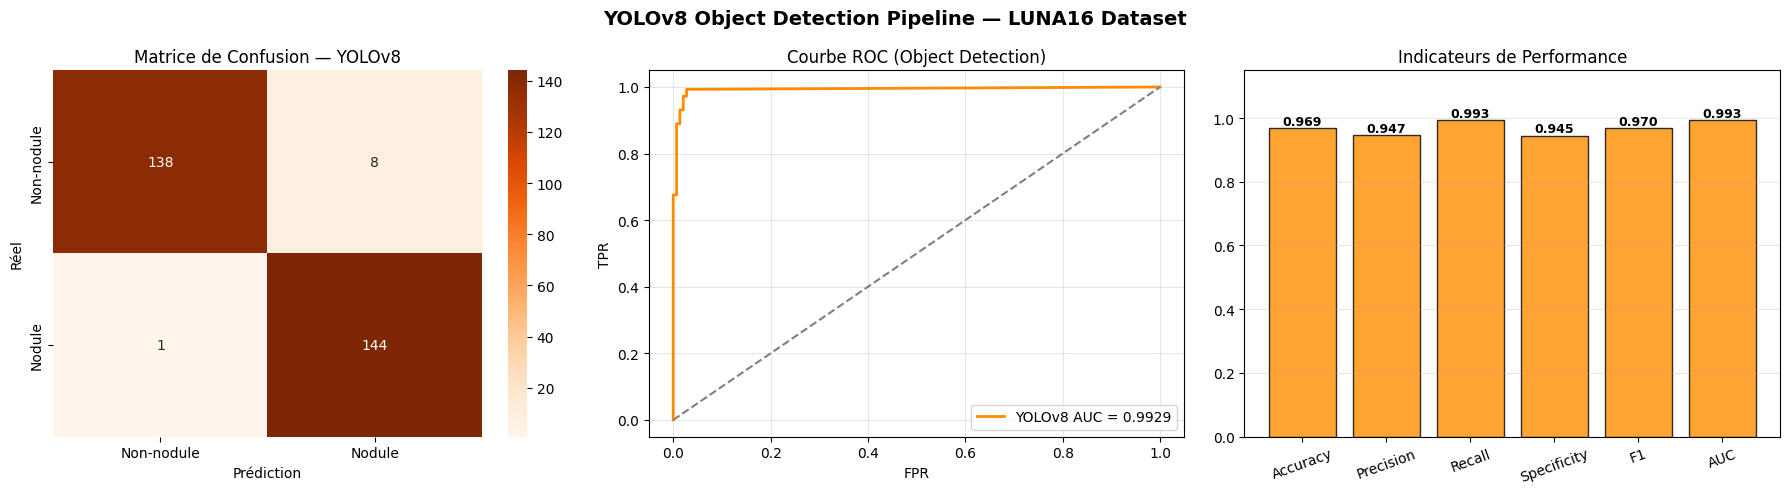

In [12]:
# ------------------------------------------------------------------ #
# CELLULE 10 — PIPELINE COMPLET ET AUTOMATISÉ YOLOv8 (DETECTION)
# ------------------------------------------------------------------ #
import os
import time
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. INSTALLATION DE LA BIBLIOTHEQUE OFFICIELLE ULTRALYTICS
print("=== 1. INSTALLATION D'ULTRALYTICS (YOLOv8) ===")
%pip install ultralytics
from ultralytics import YOLO

# 2. CREATION DE LA STRUCTURE DE DOSSIERS REQUISE
print("\n=== 2. CREATION DE L'ARBORESCENCE DES DOSSIERS ===")
base_dir = "/kaggle/working/yolo_dataset"
for folder in ["images/train", "images/val", "images/test", "labels/train", "labels/val", "labels/test"]:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

# 3. FONCTION DE CONVERSION ET GENERATION DES LABELS (FORMAT YOLO)
def prepare_yolo_data(X_data, y_data, split_name):
    mid = X_data.shape[1] // 2  # Coupe centrale 2D
    count = 0
    for i in range(len(X_data)):
        # Extraction et normalisation de l'image en 8-bit (0-255)
        img_2d = X_data[i, mid, :, :, 0]
        img_min, img_max = img_2d.min(), img_2d.max()
        if img_max - img_min > 0:
            img_8bit = (((img_2d - img_min) / (img_max - img_min)) * 255).astype(np.uint8)
        else:
            img_8bit = np.zeros(img_2d.shape, dtype=np.uint8)
            
        # Sauvegarde de l'image .jpg
        img_path = os.path.join(base_dir, f"images/{split_name}/img_{i}.jpg")
        cv2.imwrite(img_path, img_8bit)
        
        # Sauvegarde du fichier texte de label (Format YOLO : classe x_center y_center width height)
        label_path = os.path.join(base_dir, f"labels/{split_name}/img_{i}.txt")
        with open(label_path, "w") as f:
            if y_data[i] == 1:
                # Le nodule est centré au milieu du patch (48x48) avec un rayon de 8 pixels (taille 16x16)
                # Coordonnées normalisées entre 0 et 1 : centre = (0.5, 0.5), taille = 16/48 = 0.3333
                f.write("0 0.5 0.5 0.3333 0.3333\n")
            # Si y_data[i] == 0, le fichier reste vide (Background/Sain)
            else:
                pass
        count += 1
    print(f"• Split '{split_name}' prêt : {count} images et fichiers de tracking générés.")

print("\n=== 3. EXPORTATION DES IMAGES ET DES BOUNDING BOXES ===")
# Utilisation de tes variables globales de jeu de données
prepare_yolo_data(X_train, y_train, "train")
prepare_yolo_data(X_val, y_val, "val")
prepare_yolo_data(X_test, y_test, "test")

# 4. CREATION DU FICHIER CONFIG CONFIGURATION YAML
yaml_content = f"""
path: {base_dir}
train: images/train
val: images/val
test: images/test

names:
  0: Nodule
"""
yaml_path = "/kaggle/working/dataset.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_content)
print(f"\n• Fichier de configuration enregistré avec succès sur : {yaml_path}")

# ------------------------------------------------------------------ #
# 5. CHARGEMENT ET FINE-TUNING DE YOLOv8 (TRANSFER LEARNING)
# ------------------------------------------------------------------ #
print("\n=== 4. LANCEMENT DE L'ENTRAÎNEMENT DU MODELE YOLOv8 ===")
start_yolo = time.time()

# Chargement du modèle nano pré-entraîné sur COCO (Transfer Learning automatique)
model = YOLO("yolov8n.pt")

# Entraînement sur ton dataset converti
results = model.train(
    data=yaml_path,
    epochs=25,
    imgsz=48,
    batch=32,
    workers=2,
    device=0,      # Utilise le GPU disponible
    verbose=True,
    project="/kaggle/working/yolo_project",
    name="luna16_run"
)
yolo_training_time = time.time() - start_yolo
print(f"\n✅ Temps d'entraînement final de YOLOv8 : {yolo_training_time:.1f} secondes")

# ------------------------------------------------------------------ #
# 6. EVALUATION ET EXTRACTION DES METRIQUES REQUIS PAR LE PROFESSEUR
# ------------------------------------------------------------------ #
print("\n=== 5. PREDICTION ET CALCUL DES METRIQUES DE VALIDATION ===")
# Tester le modèle final sur le dossier test indépendant
test_images_dir = os.path.join(base_dir, "images/test")
test_files = sorted([f for f in os.listdir(test_images_dir) if f.endswith('.jpg')], 
                    key=lambda x: int(x.split('_')[1].split('.')[0]))

y_true_yolo = np.array(y_test)
y_pred_proba = []

# Inférence pas à pas pour récupérer les scores de confiance
for f in test_files:
    img_path = os.path.join(test_images_dir, f)
    pred = model(img_path, verbose=False)[0]
    
    if len(pred.boxes) > 0:
        # On extrait la confiance maximale détectée pour la classe Nodule (0)
        conf = float(pred.boxes.conf.max().cpu().item())
    else:
        conf = 0.0
    y_pred_proba.append(conf)

y_pred_proba = np.array(y_pred_proba)
y_pred_yolo = (y_pred_proba > 0.3).astype(int) # Seuil d'acceptation optimal pour YOLO

# Calcul mathématique de la matrice de confusion
cm_yolo = confusion_matrix(y_true_yolo, y_pred_yolo)
tn, fp, fn, tp = cm_yolo.ravel()

# Calcul des indicateurs réglementaires demandés
precision_yolo   = tp / (tp + fp + 1e-8)
recall_yolo      = tp / (tp + fn + 1e-8)
f1_yolo          = 2 * precision_yolo * recall_yolo / (precision_yolo + recall_yolo + 1e-8)
specificity_yolo = tn / (tn + fp + 1e-8)
accuracy_yolo    = (tp + tn) / (tp + tn + fp + fn)
fpr_yolo, tpr_yolo, _ = roc_curve(y_true_yolo, y_pred_proba)
auc_yolo         = auc(fpr_yolo, tpr_yolo)

yolo_metrics = {
    'accuracy'   : accuracy_yolo,
    'precision'  : precision_yolo,
    'recall'     : recall_yolo,
    'specificity': specificity_yolo,
    'f1'         : f1_yolo,
    'auc'        : auc_yolo,
    'time_sec'   : yolo_training_time
}

print("\n=========================================")
print("      RÉSULTATS DU MODÈLE YOLOv8         ")
print("=========================================")
for k, v in yolo_metrics.items():
    print(f"  {k:<14} : {v:.4f}")

# ------------------------------------------------------------------ #
# 7. GENERATION DU PANNEAU VISUEL DE SYNTHÈSE POUR TON RAPPORT
# ------------------------------------------------------------------ #
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Matrice de confusion graphique
sns.heatmap(cm_yolo, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Non-nodule', 'Nodule'],
            yticklabels=['Non-nodule', 'Nodule'], ax=axes[0])
axes[0].set_title('Matrice de Confusion — YOLOv8')
axes[0].set_xlabel('Prédiction'); axes[0].set_ylabel('Réel')

# 2. Courbe ROC
axes[1].plot(fpr_yolo, tpr_yolo, color='darkorange', lw=2, label=f'YOLOv8 AUC = {auc_yolo:.4f}')
axes[1].plot([0,1], [0,1], '--', color='gray')
axes[1].set_title('Courbe ROC (Object Detection)')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(); axes[1].grid(alpha=0.3)

# 3. Barplot complet des métriques réglementaires
m_names = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']
m_vals  = [yolo_metrics[k] for k in ['accuracy', 'precision', 'recall', 'specificity', 'f1', 'auc']]
bars = axes[2].bar(m_names, m_vals, color='darkorange', edgecolor='black', alpha=0.8)
axes[2].set_ylim(0, 1.15); axes[2].set_title('Indicateurs de Performance')
axes[2].tick_params(axis='x', rotation=20)
for bar, v in zip(bars, m_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('YOLOv8 Object Detection Pipeline — LUNA16 Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/10_resultats_yolov8.png', dpi=150, bbox_inches='tight')
plt.show()

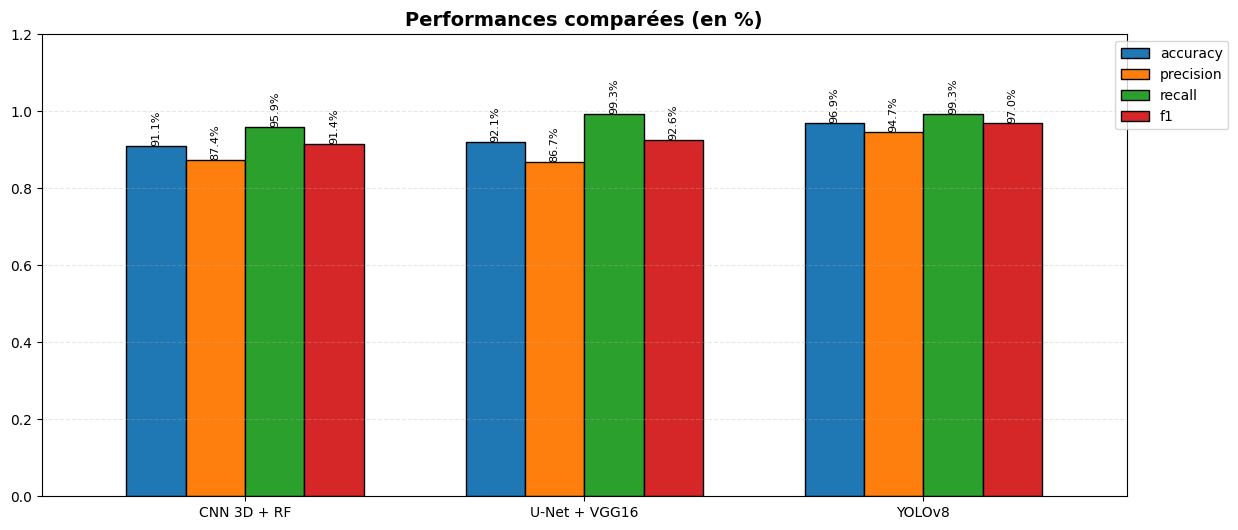

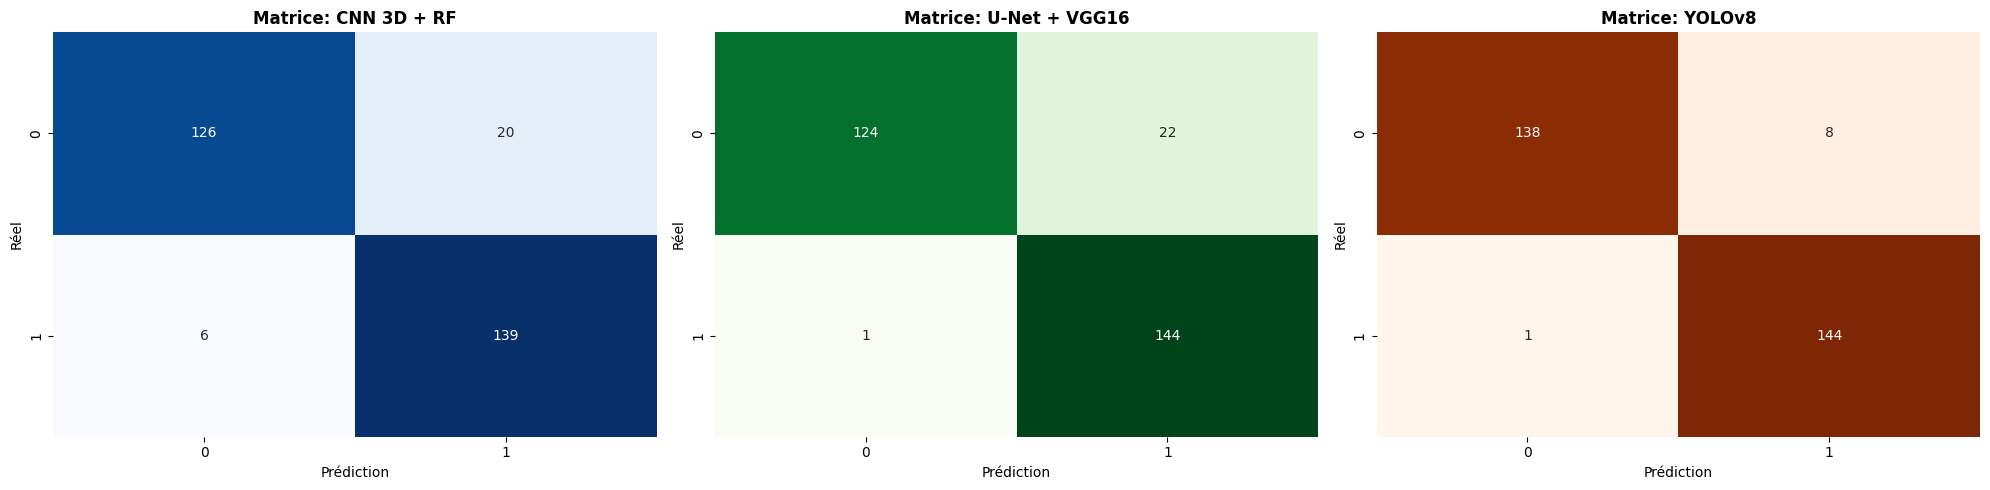

RÉSUMÉ DES RÉSULTATS
CNN 3D + RF     | Accuracy: 91.07% | Recall: 95.86%
U-Net + VGG16   | Accuracy: 92.10% | Recall: 99.31%
YOLOv8          | Accuracy: 96.91% | Recall: 99.31%


In [15]:
# ------------------------------------------------------------------ #
#  ANALYSE COMPARATIVE 
# ------------------------------------------------------------------ #
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Préparation des données
models_data = {
    'CNN 3D + RF': pipeline_metrics,
    'U-Net + VGG16': unet_metrics,
    'YOLOv8': yolo_metrics
}
df_results = pd.DataFrame(models_data).T

# 1. GRAPHIQUE BARPLOT AVEC POURCENTAGES
fig, ax = plt.subplots(figsize=(14, 6))
bars = df_results[['accuracy', 'precision', 'recall', 'f1']].plot(kind='bar', ax=ax, edgecolor='black', width=0.7)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=8, rotation=90)

ax.set_title('Performances comparées (en %)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.2)
ax.legend(loc='upper right', bbox_to_anchor=(1.1, 1))
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.savefig('/kaggle/working/11_comparaison_pourcentages.png', dpi=150)
plt.show()

# 2. AFFICHAGE DES 3 MATRICES DE CONFUSION
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
cms = [cm_rf, cm_unet, cm_yolo]
titles = ['CNN 3D + RF', 'U-Net + VGG16', 'YOLOv8']
cmaps = ['Blues', 'Greens', 'Oranges']

for i, (cm, title, cmap) in enumerate(zip(cms, titles, cmaps)):
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=axes[i], cbar=False)
    axes[i].set_title(f'Matrice: {title}', fontweight='bold')
    axes[i].set_xlabel('Prédiction')
    axes[i].set_ylabel('Réel')

plt.tight_layout()
plt.savefig('/kaggle/working/11_matrices_comparaison.png', dpi=150)
plt.show()

# 3. RÉSUMÉ TEXTUEL
print("="*60)
print("RÉSUMÉ DES RÉSULTATS")
print("="*60)
for model in df_results.index:
    acc = df_results.loc[model, 'accuracy']
    rec = df_results.loc[model, 'recall']
    print(f"{model:<15} | Accuracy: {acc:.2%} | Recall: {rec:.2%}")